# 🛡️ PhishSentinel: Agentic AI-Based Phishing Email Detection and Explanation System

**Project title:** *Agentic AI-Based Phishing Email Detection and Explanation System*

PhishSentinel is a **multi-agent system built on LangGraph** that analyses an email the way a Security Operations Centre (SOC) team would:

* specialised **forensic agents** (headers, URLs, content, obfuscation) run **in parallel**,
* a **machine-learning agent** gives a statistical second opinion,
* a **learned evidence-fusion router** decides whether the case is easy (**fast path**) or ambiguous (**deep path**),
* in the deep path a **Social-Engineering Linguist** and a **RAG Threat-Intelligence agent** (grounded in MITRE ATT&CK) feed a **Judge**, whose verdict is challenged by a **red-team Critic** in a debate loop,
* an **Explainer agent** and a **Response agent** produce a plain-English explanation, extracted IOCs and an incident-response playbook.

### What makes this project stand out
| # | Feature | Why it matters |
|---|---|---|
| 1 | **Adaptive compute routing** | Only ambiguous emails reach the LLM agents. Easy ones are settled in milliseconds, which cuts LLM cost by roughly 10–50×. |
| 2 | **Judge ↔ Critic debate loop** | A red-team agent challenges every verdict, and the Judge must answer the challenge before the case closes. |
| 3 | **Hybrid RAG (FAISS dense + TF-IDF sparse, Reciprocal-Rank Fusion)** with **citation-grounding checks** | Each MITRE technique the LLM cites is checked against the retrieved documents. Made-up citations are dropped and counted. |
| 4 | **Learned evidence fusion** | A stacked logistic model combines the ML probability with the rule log-odds. The weights are learned, not hand-tuned. |
| 5 | **Adversarial robustness test** | Homoglyph and zero-width-character attacks are run against the ML model, and a Unicode normalisation defence is shown. |
| 6 | **Explainability by design** | Colour-coded highlighted email, evidence ledger in log-odds, agent timeline (Gantt) and a summary for employees. |
| 7 | **Human-in-the-loop memory** | Analyst feedback is stored in a vector memory and changes future verdicts on similar emails. |
| 8 | **Actionable output** | IOCs as STIX-like JSON plus a response playbook in the style of NIST SP 800-61. |
| 9 | **Switchable LLM backend** | Ollama (local), Groq, Gemini or OpenAI through one OpenAI-compatible client. Deterministic fallback if none is available. |

### Architecture
```
                        ┌──────────────┐
      email / raw MIME ►│ Parser Agent │  headers · URLs (incl. "www . x . com") · Unicode normalisation map
                        └──────┬───────┘
      ┌──────────────┬─────────┼──────────────┬──────────────┐          (parallel fan-out)
      ▼              ▼         ▼              ▼              ▼
  Header         URL-Intel   Content &      ML Classifier   Memory Agent
  Forensics      Agent       Obfuscation    Agent           (analyst feedback)
      └──────────────┴─────────┼──────────────┴──────────────┘
                               ▼
                    ┌─────────────────────┐   confident?
                    │ Router: learned     │──── yes ───────────────────┐
                    │ evidence fusion     │                            │  FAST PATH
                    └─────────┬───────────┘                            │
                         no   │ DEEP PATH                              │
               ┌──────────────┴───────────────┐                        │
               ▼                              ▼                        │
     Social-Engineering              Threat-Intel RAG Agent            │
     Linguist (LLM)                  (FAISS + TF-IDF → LLM, grounded)  │
               └──────────────┬───────────────┘                        │
                              ▼                                        │
                       Judge (LLM)  ◄──── rebuttal ────┐               │
                              ▼                        │               │
                       Critic / Red-team (LLM) ─ disagrees             │
                              ▼ agrees                                 │
                        ┌──────────┐◄─────────────────────────────────┘
                        │ Finalize │  → SAFE / SUSPICIOUS / PHISHING
                        └────┬─────┘
                 ┌───────────┴───────────┐    (report mode)
                 ▼                       ▼
         Explainer (LLM)          Response Agent (IOCs + playbook)
```

## 1. Setup
* **Google Colab:** run the cells in order. For the LLM, add **one** key under 🔑 *Secrets*: `GROQ_API_KEY` (free and fast, recommended), `GEMINI_API_KEY` or `OPENAI_API_KEY`.
* **Local:** install [Ollama](https://ollama.com) and run `ollama pull llama3`. It is detected automatically.
* **No LLM available:** the agents fall back to deterministic reasoning, so the notebook still runs from start to finish.

> The outputs saved in this notebook were produced with **Meta Llama-3 8B running locally through Ollama** on an Apple M2 Pro.

In [1]:
import sys, subprocess, importlib.util
REQUIRED = {"langgraph": "langgraph", "openai": "openai", "faiss": "faiss-cpu",
            "sentence_transformers": "sentence-transformers", "sklearn": "scikit-learn"}
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)
print("All dependencies available ✔")

All dependencies available ✔


In [2]:
import os, re, json, time, math, random, hashlib, operator, unicodedata, html, threading, warnings, urllib.request
from email import message_from_string, policy
from email.utils import parseaddr
from urllib.parse import urlparse, parse_qs
from typing import TypedDict, Annotated

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve)

warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
C = {"phish": "#d1495b", "legit": "#2e8b57", "warn": "#e09f3e", "blue": "#00798c", "grey": "#6c757d", "ink": "#30343f", "purple": "#6a4c93"}

## 2. LLM layer: one client for every backend
Ollama, Groq, Gemini and OpenAI all offer an **OpenAI-compatible** API, so one wrapper covers them all. It adds:
* **JSON-mode** prompting with tolerant parsing and retries,
* a **disk cache** (`llm_cache.json`), so re-runs are fast and give the same results,
* **telemetry** (calls, latency, cache hits) for the cost analysis in Section 10.

In [3]:
def _secret(name):
    """Read a key from the environment or from Colab Secrets."""
    if os.getenv(name):
        return os.getenv(name)
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None

class LLM:
    def __init__(self, cache_path="llm_cache.json"):
        self.backend, self.model, self.client = self._detect()
        self.cache_path = cache_path
        self.cache = json.load(open(cache_path)) if os.path.exists(cache_path) else {}
        self.lock = threading.Lock()
        self.calls = self.cache_hits = self.failures = 0
        self.latency = 0.0

    def _detect(self):
        from openai import OpenAI
        if _secret("GROQ_API_KEY"):
            return "groq", os.getenv("LLM_MODEL", "llama-3.1-8b-instant"), OpenAI(
                base_url="https://api.groq.com/openai/v1", api_key=_secret("GROQ_API_KEY"))
        if _secret("GEMINI_API_KEY"):
            return "gemini", os.getenv("LLM_MODEL", "gemini-2.5-flash"), OpenAI(
                base_url="https://generativelanguage.googleapis.com/v1beta/openai/", api_key=_secret("GEMINI_API_KEY"))
        if _secret("OPENAI_API_KEY"):
            return "openai", os.getenv("LLM_MODEL", "gpt-4o-mini"), OpenAI(api_key=_secret("OPENAI_API_KEY"))
        try:
            tags = json.load(urllib.request.urlopen("http://localhost:11434/api/tags", timeout=2))
            names = [m["name"] for m in tags.get("models", [])]
            if names:
                model = os.getenv("LLM_MODEL") or next((n for n in names if n.startswith("llama3")), names[0])
                return "ollama", model, OpenAI(base_url="http://localhost:11434/v1", api_key="ollama")
        except Exception:
            pass
        return "offline", None, None

    @property
    def available(self):
        return self.client is not None

    @staticmethod
    def parse_json(text):
        text = re.sub(r"^```(?:json)?|```$", "", (text or "").strip(), flags=re.M).strip()
        for candidate in (text, (re.search(r"\{.*\}", text, flags=re.S) or [None])[0]):
            if candidate:
                try:
                    return json.loads(candidate)
                except Exception:
                    pass
        return None

    def chat_json(self, system, user, max_tokens=600):
        if not self.available:
            return None
        key = hashlib.sha256(f"{self.model}|{system}|{user}".encode()).hexdigest()
        with self.lock:
            if key in self.cache:
                self.cache_hits += 1
                return self.cache[key]
        messages = [{"role": "system", "content": system + "\nRespond with ONLY one valid JSON object, no prose."},
                    {"role": "user", "content": user}]
        for attempt in range(3):
            try:
                t = time.perf_counter()
                kwargs = dict(model=self.model, messages=messages, temperature=0, max_tokens=max_tokens)
                if attempt < 2:
                    kwargs["response_format"] = {"type": "json_object"}
                resp = self.client.chat.completions.create(**kwargs)
                out = self.parse_json(resp.choices[0].message.content)
                with self.lock:
                    self.calls += 1
                    self.latency += time.perf_counter() - t
                if isinstance(out, dict):
                    with self.lock:
                        self.cache[key] = out
                    return out
            except Exception:
                time.sleep(1.5 * (attempt + 1))
        with self.lock:
            self.failures += 1
        return None

    def save(self):
        with self.lock:
            json.dump(self.cache, open(self.cache_path, "w"))

    def stats(self):
        return {"backend": self.backend, "model": self.model, "live_calls": self.calls, "cache_hits": self.cache_hits,
                "failures": self.failures, "avg_latency_s": round(self.latency / max(self.calls, 1), 2)}

llm = LLM()
print("LLM backend:", llm.backend, "| model:", llm.model)
if llm.available:
    print("Smoke test →", llm.chat_json("You are a helpful assistant.", 'Return {"status": "ready"}'))

LLM backend: ollama | model: llama3:latest


Smoke test → {'status': 'ready'}


## 3. Dataset
We use the public **Phishing Email Dataset** ([`zefang-liu/phishing-email-dataset`](https://huggingface.co/datasets/zefang-liu/phishing-email-dataset), LGPL-3.0, 18,650 emails). It combines several well-known corpora, including Enron and other phishing/spam collections, into binary labels: *Phishing Email* or *Safe Email*.

Cleaning steps: drop empty or very short texts, remove **exact duplicates** (so near-identical copies cannot leak between train and test), and drop extreme outliers longer than 20k characters. We then make a stratified **train (64%) / validation (16%) / test (20%)** split. The validation split is used **only** to learn the evidence-fusion weights.

In [4]:
DATA_URL = "https://huggingface.co/datasets/zefang-liu/phishing-email-dataset/resolve/main/Phishing_Email.csv"
DATA_PATH = "data/Phishing_Email.csv"
if not os.path.exists(DATA_PATH):
    os.makedirs("data", exist_ok=True)
    print("Downloading dataset …")
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

raw_df = pd.read_csv(DATA_PATH)
df = raw_df.rename(columns={"Email Text": "text", "Email Type": "type"})[["text", "type"]].dropna()
df["text"] = df["text"].astype(str)
df = df[df.text.str.strip().str.len() > 20].drop_duplicates("text")
df = df[df.text.str.len() < 20_000].reset_index(drop=True)
df["label"] = (df["type"] == "Phishing Email").astype(int)

train_full, test_df = train_test_split(df, test_size=0.20, stratify=df.label, random_state=SEED)
train_df, val_df = train_test_split(train_full, test_size=0.20, stratify=train_full.label, random_state=SEED)
print(f"raw rows: {len(raw_df):,} → clean rows: {len(df):,}")
print(f"train {len(train_df):,} | validation {len(val_df):,} | test {len(test_df):,}")
display(df.groupby("type").agg(n=("text", "size"), median_chars=("text", lambda s: int(s.str.len().median())),
                               has_link=("text", lambda s: round(s.str.contains(r"https?\s*:|www\s*\.", regex=True).mean(), 3))))

raw rows: 18,650 → clean rows: 17,432
train 11,156 | validation 2,789 | test 3,487


,n,median_chars,has_link
type,,,
Phishing Email,6519,762,0.378
Safe Email,10913,1015,0.415


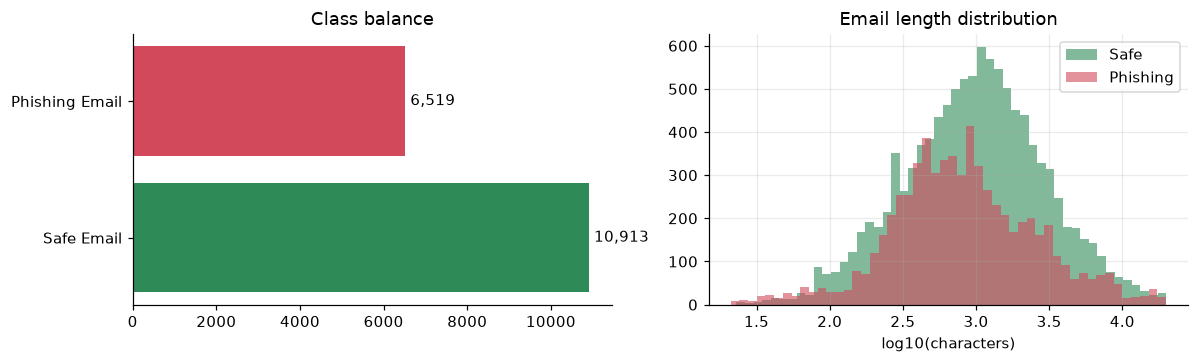

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
counts = df["type"].value_counts()
ax[0].barh(counts.index, counts.values, color=[C["legit"] if "Safe" in i else C["phish"] for i in counts.index])
for i, v in enumerate(counts.values):
    ax[0].text(v, i, f" {v:,}", va="center")
ax[0].set_title("Class balance"); ax[0].grid(False)
for lab, col in [(0, C["legit"]), (1, C["phish"])]:
    ax[1].hist(np.log10(df[df.label == lab].text.str.len()), bins=50, alpha=0.6, color=col,
               label="Safe" if lab == 0 else "Phishing")
ax[1].set_xlabel("log10(characters)"); ax[1].set_title("Email length distribution"); ax[1].legend()
plt.tight_layout(); plt.show()

## 4. Parser agent: MIME parsing, URL extraction and Unicode normalisation
Attackers hide keywords with **homoglyphs** (Cyrillic `а` in place of Latin `a`) and **zero-width characters**. The parser builds a normalised view of the text **plus an index map back to the original**. Detectors run on the clean text, while the highlights are still drawn on the exact characters the user saw.

It also handles:
* full **raw MIME emails** (headers, SPF/DKIM/DMARC, Reply-To, attachments) when they are pasted into the system,
* the dataset's tokenised URL style (`www . example . com`), which ordinary URL regexes miss.

In [6]:
ZW_RE = re.compile("[\u200b\u200c\u200d\u2060\ufeff\u00ad]")
CONFUSABLES = {  # Cyrillic / Greek look-alikes → Latin
    "а": "a", "е": "e", "о": "o", "р": "p", "с": "c", "у": "y", "х": "x", "і": "i", "ј": "j", "ѕ": "s", "ԁ": "d", "һ": "h",
    "ӏ": "l", "ԛ": "q", "ԝ": "w", "А": "A", "В": "B", "Е": "E", "К": "K", "М": "M", "Н": "H", "О": "O", "Р": "P", "С": "C",
    "Т": "T", "Х": "X", "ο": "o", "α": "a", "ν": "v", "ρ": "p", "τ": "t", "ι": "i", "κ": "k", "Ο": "O", "Α": "A", "Ε": "E",
}

def normalize_with_map(s):
    """Return (normalised_text, index_map, stats). index_map[i] = position in the original string."""
    out, idx, zw, glyph = [], [], 0, 0
    for i, ch in enumerate(s):
        if ZW_RE.match(ch):
            zw += 1
            continue
        n = unicodedata.normalize("NFKC", ch)
        mapped = "".join(CONFUSABLES.get(c, c) for c in n)
        if mapped != ch and ch in CONFUSABLES:
            glyph += 1
        for c in mapped:
            out.append(c); idx.append(i)
    return "".join(out), idx, {"zero_width": zw, "homoglyphs": glyph}

def normalize(s):
    return normalize_with_map(s)[0]

URL_RE = re.compile(r"(?i)\b(?:https?://|www\.)[^\s<>\"')\]]+")
SPACED_URL_RE = re.compile(r"(?i)\b(?:https?\s*:\s*/\s*/\s*|www\s*\.\s*)[a-z0-9-]+(?:\s*\.\s*[a-z0-9-]+)+(?:\s*/\s*[\w\-.?=&%~]+)*")
MULTI_TLDS = {"co.uk", "co.in", "com.au", "net.in", "org.in", "co.jp", "com.br"}

def registered_domain(host):
    parts = (host or "").lower().strip(".").split(".")
    if len(parts) >= 3 and ".".join(parts[-2:]) in MULTI_TLDS:
        return ".".join(parts[-3:])
    return ".".join(parts[-2:])

def extract_urls(norm_text):
    found, seen = [], set()
    for rx in (URL_RE, SPACED_URL_RE):
        for m in rx.finditer(norm_text):
            if any(a <= m.start() < b for a, b in seen):
                continue
            url = re.sub(r"\s+", "", m.group(0)).rstrip(".,;")
            full = url if url.lower().startswith("http") else "http://" + url
            host = (urlparse(full).hostname or "").lower()
            if "." not in host:
                continue
            seen.add((m.start(), m.end()))
            found.append({"url": url, "host": host, "domain": registered_domain(host),
                          "scheme": urlparse(full).scheme if url.lower().startswith("http") else "", "span": (m.start(), m.end())})
    return found

def looks_like_raw_email(s):
    head = s[:3000]
    return bool(re.search(r"(?im)^from:\s.+$", head) and re.search(r"(?im)^(subject|to|received|message-id):\s", head))

def parse_input(raw):
    headers, attachments, body = None, [], raw
    if looks_like_raw_email(raw):
        msg = message_from_string(raw, policy=policy.default)
        from_name, from_addr = parseaddr(str(msg.get("From", "")))
        auth = str(msg.get("Authentication-Results", "") or "")
        res = lambda k: (re.search(rf"{k}=(\w+)", auth).group(1).lower() if re.search(rf"{k}=(\w+)", auth) else "none")
        headers = {"from_name": from_name, "from_addr": from_addr.lower(), "subject": str(msg.get("Subject", "")),
                   "reply_to": parseaddr(str(msg.get("Reply-To", "") or ""))[1].lower(),
                   "return_path": parseaddr(str(msg.get("Return-Path", "") or ""))[1].lower(),
                   "spf": res("spf"), "dkim": res("dkim"), "dmarc": res("dmarc"), "has_auth_header": bool(auth)}
        texts, htmls = [], []
        for part in msg.walk():
            if part.is_multipart():
                continue
            if part.get_filename() or part.get_content_disposition() == "attachment":
                data = part.get_payload(decode=True) or b""
                attachments.append({"filename": part.get_filename() or "unnamed", "size": len(data),
                                    "sha256": hashlib.sha256(data).hexdigest()})
            elif part.get_content_type() == "text/plain":
                texts.append(part.get_content())
            elif part.get_content_type() == "text/html":
                htmls.append(re.sub(r"<[^>]+>", " ", part.get_content()))
        body = "\n".join(texts) or "\n".join(htmls)
        if headers["subject"]:
            body = headers["subject"] + "\n\n" + body
    norm, idx, obf = normalize_with_map(body)
    return {"body": body, "norm": norm, "idx": idx, "obfuscation": obf, "headers": headers,
            "attachments": attachments, "urls": extract_urls(norm)}

demo = "Please vеrify your ac\u200bcount at www . secure-paypa1 . com / login now"
p = parse_input(demo)
print("normalised :", p["norm"]); print("obfuscation:", p["obfuscation"]); print("urls       :", [u["url"] for u in p["urls"]])

normalised : Please verify your account at www . secure-paypa1 . com / login now
obfuscation: {'zero_width': 1, 'homoglyphs': 1}
urls       : ['www.secure-paypa1.com/login']


## 5. Forensic tool agents (deterministic, explainable)
Each tool agent emits **signals**: `{id, agent, name, weight, evidence, mitre, spans}`.
Weights are **log-odds** contributions. Positive values push towards phishing and negative values push towards legitimate. This makes every verdict auditable as a simple ledger.

| Agent | Examples of signals |
|---|---|
| Header Forensics | SPF/DKIM/DMARC failure, Reply-To mismatch, display-name brand spoofing, fully authenticated sender (negative) |
| URL Intelligence | raw-IP links, shorteners, risky TLDs, brand look-alikes (`paypa1`, `rnicrosoft`), brand-in-subdomain, punycode, `@` in URL, OAuth-consent abuse |
| Content & Obfuscation | urgency, threats, credential requests, financial/reward lures, secrecy, calls to action, homoglyph/zero-width evasion, reply-thread context (negative) |

In [7]:
BRANDS = {"paypal": ["paypal.com"], "microsoft": ["microsoft.com", "microsoftonline.com", "office.com", "live.com", "outlook.com"],
          "apple": ["apple.com", "icloud.com"], "amazon": ["amazon.com", "amazon.in", "amazon.co.uk"], "netflix": ["netflix.com"],
          "google": ["google.com", "gmail.com", "youtube.com"], "ebay": ["ebay.com"], "docusign": ["docusign.com", "docusign.net"],
          "dhl": ["dhl.com"], "fedex": ["fedex.com"], "chase": ["chase.com"], "wellsfargo": ["wellsfargo.com"],
          "bankofamerica": ["bankofamerica.com"], "citibank": ["citi.com", "citibank.com"], "hdfc": ["hdfcbank.com"], "linkedin": ["linkedin.com"]}
LEGIT_DOMAINS = {d for ds in BRANDS.values() for d in ds}
SHORTENERS = {"bit.ly", "tinyurl.com", "goo.gl", "t.co", "ow.ly", "is.gd", "buff.ly", "rebrand.ly", "cutt.ly", "shorturl.at", "tiny.cc"}
RISKY_TLDS = {"xyz", "top", "club", "icu", "buzz", "live", "info", "biz", "ru", "cn", "tk", "ml", "ga", "cf", "gq", "zip", "mov", "online", "site", "shop"}
FREEMAIL = {"gmail.com", "yahoo.com", "outlook.com", "hotmail.com", "protonmail.com", "aol.com", "mail.ru"}
RISKY_EXT = {"exe", "scr", "js", "vbs", "bat", "cmd", "ps1", "jar", "msi", "hta", "lnk"}

def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def skeleton(label):
    s = normalize(label.lower())
    for a, b in [("rn", "m"), ("vv", "w"), ("0", "o"), ("1", "l"), ("3", "e"), ("5", "s"), ("$", "s")]:
        s = s.replace(a, b)
    return s

def brand_lookalike(host):
    """Return (brand, kind) if host imitates a brand without belonging to it."""
    dom = registered_domain(host)
    if dom in LEGIT_DOMAINS:
        return None
    label = skeleton(dom.split(".")[0])
    for brand in BRANDS:
        if label == brand or (len(brand) >= 5 and levenshtein(label, brand) <= 1):
            return brand, "typosquat"
        if len(brand) >= 4 and brand in label.replace("-", ""):
            return brand, "brand-in-domain"
        if any(brand == skeleton(part) for part in host.split(".")[:-2]):
            return brand, "brand-in-subdomain"
    return None

def sig(sid, agent, name, weight, evidence, mitre=None, spans=None, category=None):
    return {"id": sid, "agent": agent, "name": name, "weight": round(weight, 2), "evidence": evidence,
            "mitre": mitre, "spans": spans or [], "category": category or name}

def header_forensics(e):
    h = e["headers"]
    if not h:
        return []
    out, fdom = [], h["from_addr"].split("@")[-1]
    if h["has_auth_header"]:
        for k, w in [("spf", 1.0), ("dkim", 0.6), ("dmarc", 1.3)]:
            if h[k] in ("fail", "softfail", "none", "permerror"):
                out.append(sig(f"H-{k}", "Header", f"{k}_{h[k]}", w * (0.5 if h[k] in ("softfail", "none") else 1), f"{k.upper()}={h[k]}", "T1566"))
        if all(h[k] == "pass" for k in ("spf", "dkim", "dmarc")):
            out.append(sig("H-auth", "Header", "fully_authenticated", -0.8, f"SPF/DKIM/DMARC pass for {fdom}"))
    if h["reply_to"] and h["reply_to"].split("@")[-1] != fdom:
        out.append(sig("H-reply", "Header", "reply_to_mismatch", 1.4, f"Reply-To {h['reply_to']} ≠ From domain {fdom}", "T1656"))
    if h["return_path"] and registered_domain(h["return_path"].split("@")[-1]) != registered_domain(fdom):
        out.append(sig("H-rpath", "Header", "return_path_mismatch", 0.5, f"Return-Path {h['return_path']}"))
    disp = skeleton(h["from_name"].replace(" ", ""))
    for brand, doms in BRANDS.items():
        if brand in disp and registered_domain(fdom) not in doms:
            out.append(sig("H-spoof", "Header", "display_name_spoof", 2.0, f"Display name '{h['from_name']}' but sent from {fdom}", "T1656"))
            break
    if fdom in FREEMAIL and re.search(r"(?i)\b(ceo|cfo|director|president|payroll|accounts)\b", h["from_name"]):
        out.append(sig("H-free", "Header", "executive_on_freemail", 1.5, f"Executive title on free-mail domain {fdom}", "T1656"))
    for a in e["attachments"]:
        parts = a["filename"].lower().split(".")
        if parts[-1] in RISKY_EXT:
            out.append(sig("A-exe", "Header", "executable_attachment", 3.0, a["filename"], "T1566.001"))
        if len(parts) >= 3 and parts[-2] in {"pdf", "doc", "docx", "xls", "jpg", "txt"}:
            out.append(sig("A-dbl", "Header", "double_extension", 2.5, a["filename"], "T1036.007"))
        if parts[-1] in {"docm", "xlsm", "html", "htm", "iso", "img"}:
            out.append(sig("A-risky", "Header", "risky_container", 1.5, a["filename"], "T1566.001"))
    return out

def url_intel(e):
    out, urls = [], e["urls"]
    for u in urls:
        host, sp = u["host"], [u["span"]]
        if re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", host):
            out.append(sig("U-ip", "URL", "raw_ip_link", 2.0, u["url"], "T1566.002", sp, "url"))
        if u["domain"] in SHORTENERS:
            out.append(sig("U-short", "URL", "url_shortener", 0.8, u["url"], "T1566.002", sp, "url"))
        if host.split(".")[-1] in RISKY_TLDS:
            out.append(sig("U-tld", "URL", "risky_tld", 0.7, f".{host.split('.')[-1]} in {host}", "T1583.001", sp, "url"))
        if host.startswith("xn--") or ".xn--" in host:
            out.append(sig("U-puny", "URL", "punycode_domain", 2.5, host, "T1583.001", sp, "url"))
        la = brand_lookalike(host)
        if la:
            out.append(sig("U-look", "URL", f"brand_lookalike_{la[1]}", 2.2, f"{host} imitates {la[0]}", "T1583.001", sp, "url"))
        if "@" in u["url"].split("//")[-1].split("/")[0]:
            out.append(sig("U-at", "URL", "at_symbol_in_url", 1.5, u["url"], "T1566.002", sp, "url"))
        q = parse_qs(urlparse(u["url"] if u["url"].startswith("http") else "http://" + u["url"]).query)
        if "redirect_uri" in q and "scope" in q:
            redir = registered_domain(urlparse(q["redirect_uri"][0]).hostname or "")
            if redir not in LEGIT_DOMAINS:
                out.append(sig("U-oauth", "URL", "oauth_consent_abuse", 2.5, f"OAuth grant ({q['scope'][0][:60]}) redirecting to {redir}", "T1528", sp, "url"))
    if len(urls) >= 6:
        out.append(sig("U-many", "URL", "many_links", 0.3, f"{len(urls)} links in message", None))
    if urls and all(u["domain"] in LEGIT_DOMAINS for u in urls):
        out.append(sig("U-trust", "URL", "links_to_known_brands_only", -0.6, ", ".join(sorted({u['domain'] for u in urls}))))
    return out

CONTENT_RULES = [  # (id, name, log-odds weight, MITRE, patterns)
    ("C-urg", "urgency", 0.5, "T1566", [r"\b(urgent(ly)?|immediately|act now|right away|within \d+ (hours?|days?)|expires? (today|soon)|final notice|last chance|limited time)\b"]),
    ("C-thr", "threat", 0.7, "T1566", [r"\b(suspend(ed)?|locked|terminat(e|ed|ion)|deactivat(e|ed)|legal action|closed permanently)\b"]),
    ("C-cred", "credential_request", 1.2, "T1598", [r"\b(verify|confirm|update|validate) (your )?(account|identity|password|login|details|information|billing)\b",
                                                   r"\b(password|pin number|otp|social security|credit card (number|details)|bank account (number|details))\b"]),
    ("C-fin", "financial_lure", 0.6, "T1656", [r"\b(wire transfer|western union|money ?gram|gift cards?|bitcoin|investment opportunity|stock (alert|pick|profile)|beneficiary|inheritance|next of kin)\b"]),
    ("C-rew", "reward_lure", 0.8, "T1566", [r"\b(congratulations|you (have )?won|winner|prize|lottery|free (gift|offer|trial)|claim your|selected to receive|million (dollars|usd))\b"]),
    ("C-cta", "call_to_action", 0.6, "T1204.001", [r"\b(click (here|below|the link|this link)|visit (our|this) (site|website)|order now|buy now|sign up now|call now)\b"]),
    ("C-sec", "secrecy", 0.6, "T1656", [r"\b(keep (this|it) (between us|private|secret)|discreet(ly)?|do not (tell|share|disclose) (this|anyone))\b"]),
    ("C-gen", "generic_greeting", 0.3, "T1566", [r"\b(dear (customer|user|friend|sir|madam|valued|member|beneficiary|account holder))\b"]),
    ("C-bulk", "bulk_mail_footer", 0.4, "T1566", [r"\b(unsubscribe|remove me|opt[- ]?out|to be removed)\b"]),
    ("C-thread", "reply_thread_context", -0.7, None, [r"(-{3,}\s*original message|forwarded by|\bre\s*:\s|\bfw\s*:\s|wrote\s*:)"]),
]

def content_forensics(e):
    out, text = [], e["norm"]
    for sid, name, w, mitre, pats in CONTENT_RULES:
        spans = [(m.start(), m.end()) for p in pats for m in re.finditer(p, text, flags=re.I)]
        if spans:
            snippet = ", ".join(sorted({text[a:b].lower() for a, b in spans})[:4])
            out.append(sig(sid, "Content", name, w, f"“{snippet}”", mitre, spans[:12], name))
    obf = e["obfuscation"]
    if obf["zero_width"] or obf["homoglyphs"]:
        out.append(sig("O-evasion", "Content", "unicode_obfuscation", 1.5,
                       f"{obf['homoglyphs']} homoglyph(s), {obf['zero_width']} zero-width char(s)", "T1027", [], "obfuscation"))
    return out

e = parse_input(demo)
pd.DataFrame(header_forensics(e) + url_intel(e) + content_forensics(e))[["agent", "name", "weight", "evidence", "mitre"]]

,agent,name,weight,evidence,mitre
0,URL,brand_lookalike_brand-in-domain,2.2,www.secure-paypa1.com imitates paypal,T1583.001
1,Content,credential_request,1.2,“verify your account”,T1598
2,Content,unicode_obfuscation,1.5,"1 homoglyph(s), 1 zero-width char(s)",T1027


## 6. ML agent: TF-IDF (word + character n-grams) + logistic regression
The statistical agent learns from 11k+ labelled emails. Character n-grams pick up obfuscated spellings and word n-grams pick up phrasing. Since the model is linear, it also **explains itself**: the contribution of each term is `tf-idf × coefficient`.

The input is normalised to match the dataset style (lower-case, punctuation tokenised), so text a user pastes in looks like what the model was trained on.

ML agent trained on 11,156 emails × 305,544 features in 20.8s


Validation ROC-AUC: 0.9989 | F1: 0.9823


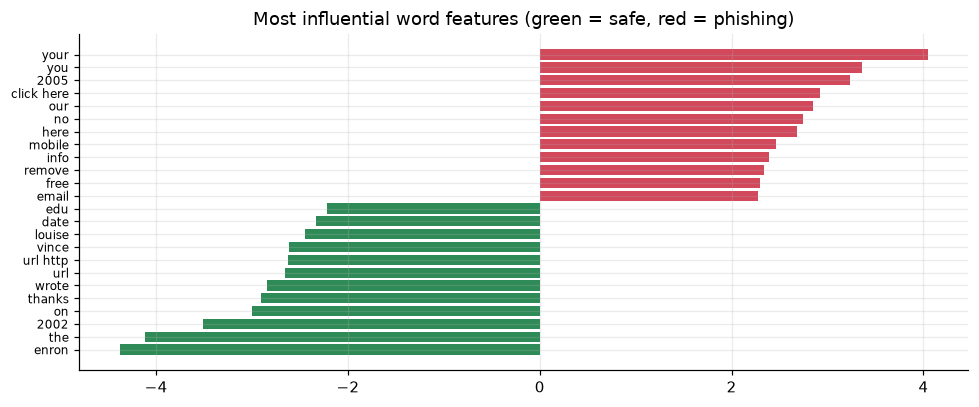

In [8]:
def ml_preprocess(text, defend=True):
    t = normalize(text) if defend else text
    t = re.sub(r"([^\w\s])", r" \1 ", t.lower())
    return re.sub(r"\s+", " ", t).strip()

word_vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=150_000, sublinear_tf=True)
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, max_features=200_000, sublinear_tf=True)
features = FeatureUnion([("word", word_vec), ("char", char_vec)])

t = time.perf_counter()
X_train = features.fit_transform(train_df.text.map(ml_preprocess))
clf = LogisticRegression(C=8.0, max_iter=3000, class_weight="balanced")
clf.fit(X_train, train_df.label)
print(f"ML agent trained on {X_train.shape[0]:,} emails × {X_train.shape[1]:,} features in {time.perf_counter()-t:.1f}s")

N_WORD = len(features.transformer_list[0][1].vocabulary_)
WORD_NAMES = features.transformer_list[0][1].get_feature_names_out()

def ml_predict(texts, defend=True):
    return clf.predict_proba(features.transform([ml_preprocess(t, defend) for t in texts]))[:, 1]

def ml_explain(text, k=6):
    x = features.transform([ml_preprocess(text)])
    xw = x[:, :N_WORD].tocoo()
    contrib = sorted(((WORD_NAMES[j], v * clf.coef_[0][j]) for j, v in zip(xw.col, xw.data)), key=lambda z: -abs(z[1]))
    return {"phish_terms": [(w, round(c, 3)) for w, c in contrib if c > 0][:k],
            "safe_terms": [(w, round(c, 3)) for w, c in contrib if c < 0][:k]}

val_ml = ml_predict(val_df.text)
print(f"Validation ROC-AUC: {roc_auc_score(val_df.label, val_ml):.4f} | F1: {f1_score(val_df.label, val_ml >= 0.5):.4f}")

coef_w = clf.coef_[0][:N_WORD]
top_p, top_s = np.argsort(coef_w)[-12:], np.argsort(coef_w)[:12]
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh([WORD_NAMES[i] for i in top_s] + [WORD_NAMES[i] for i in top_p], list(coef_w[top_s]) + list(coef_w[top_p]),
        color=[C["legit"]] * 12 + [C["phish"]] * 12)
ax.set_title("Most influential word features (green = safe, red = phishing)"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); plt.show()

## 7. RAG threat-intelligence knowledge base
The Threat-Intel agent retrieves from a curated knowledge base. It summarises **MITRE ATT&CK** techniques, **email authentication** standards, social-engineering principles and **incident-response** guidance (NIST SP 800-61, CISA).

**Hybrid retrieval:** dense semantic search (Sentence-Transformers `all-MiniLM-L6-v2` in a **FAISS** inner-product index) is fused with sparse TF-IDF keyword search using **Reciprocal Rank Fusion (RRF)**. Dense search captures meaning ("asks for login" ≈ "credential harvesting"), and sparse search captures exact terms (`DMARC`, `punycode`).

In [9]:
KB = [
    ("KB-01", "Phishing (T1566)", ["T1566"], "Adversaries send phishing messages to gain access to victim systems. Phishing is electronically delivered social engineering, either targeted (spearphishing) or non-targeted mass campaigns such as malspam. Messages typically impersonate a trusted source and induce the recipient to click a link, open an attachment or reply with information."),
    ("KB-02", "Spearphishing Attachment (T1566.001)", ["T1566.001", "T1204.002"], "Malicious files are attached to emails: Office documents with macros, HTML smuggling files, ISO/IMG containers that bypass Mark-of-the-Web, archives and executables. The text gives a plausible reason to open the file, such as an invoice, remittance advice or a shared document."),
    ("KB-03", "Spearphishing Link (T1566.002)", ["T1566.002", "T1204.001"], "Emails contain links to credential-harvesting pages or malware downloads. Common tricks: look-alike or newly registered domains, URL shorteners, open redirects, raw IP addresses, and anchor text that shows a trusted URL while the hyperlink points elsewhere. The user must click (T1204.001 Malicious Link)."),
    ("KB-04", "Phishing for Information (T1598)", ["T1598", "T1598.003"], "Messages that try to make the victim reveal sensitive information: passwords, one-time codes, card numbers, bank details or personal identity data. They often direct the victim to a fake login page or ask them to 'verify', 'confirm' or 'update' account details."),
    ("KB-05", "Impersonation (T1656)", ["T1656"], "Adversaries impersonate a trusted person or organisation, such as an executive, a vendor, IT support, a bank or a well-known brand. The aim is to get the victim to act: pay money, change bank details, buy gift cards or disclose information. Authority and urgency are combined to cut verification short."),
    ("KB-06", "Business Email Compromise and advance-fee fraud", ["T1656", "T1534"], "BEC messages often have no links or attachments. Typical signs: an availability check ('are you at your desk?'), a request for a wire transfer, gift cards or payroll change, secrecy, and a sender on free-mail or a look-alike domain. Advance-fee (419) fraud promises an inheritance, a lottery win or a share of funds in return for fees or bank details."),
    ("KB-07", "Look-alike domains and homoglyphs (T1583.001)", ["T1583.001"], "Attackers register domains that resemble trusted brands: typosquatting (paypa1, rnicrosoft), combosquatting (paypal-secure-center), the brand placed in a subdomain (paypal.com.account-review.info), and internationalised (punycode xn--) domains that use Cyrillic or Greek homoglyphs. Domains on cheap TLDs such as .xyz, .top or .icu are frequently abused."),
    ("KB-08", "Email authentication: SPF, DKIM, DMARC", ["T1566"], "SPF checks whether the sending server is authorised for the envelope domain. DKIM cryptographically signs the message. DMARC requires alignment with the visible From domain and sets the policy. Failures are strong spoofing evidence. A pass, however, only proves the mail came from that domain: attackers who own a look-alike domain can pass all three. Misconfigured legitimate senders sometimes soft-fail."),
    ("KB-09", "Display-name spoofing and Reply-To manipulation", ["T1656"], "The display name ('PayPal Security', 'CEO name') can be set to anything, while the real address is an unrelated domain. A Reply-To header that points to a different domain sends the victim's answers to the attacker. Both are classic signs of impersonation and BEC."),
    ("KB-10", "MFA fatigue / push bombing (T1621)", ["T1621"], "Attackers who already hold a password trigger repeated MFA push requests, or send a message telling the user to approve upcoming prompts, hoping the user accepts one. Legitimate IT teams never ask users to approve sign-in prompts they did not start."),
    ("KB-11", "QR-code phishing (quishing)", ["T1566.001", "T1566.002"], "The malicious URL is hidden in a QR code image or attachment, so email URL scanners do not see it, and the victim is moved to a less protected phone. Common lures are MFA re-enrolment, payroll documents and parking or payment notices."),
    ("KB-12", "OAuth consent phishing (T1528)", ["T1528"], "The victim is sent to the genuine identity-provider login page (e.g. login.microsoftonline.com) to grant a malicious third-party app broad permissions such as Mail.ReadWrite, Files.ReadWrite.All or offline_access. No password is stolen, but the attacker receives a persistent token. Signs: an OAuth authorize URL with broad scopes and a redirect_uri on an unknown domain. Remedy: revoke the grant and enable admin consent workflow."),
    ("KB-13", "Delivery and customs-fee scams", ["T1566.002", "T1598"], "Fake courier notices (DHL, FedEx, postal services) claim a parcel is held for an unpaid fee or a missing address. They link to card-harvesting pages, often through shorteners or newly registered domains, and use a small fee and a short deadline to lower suspicion."),
    ("KB-14", "Reward, lottery and gift-card lures", ["T1566", "T1598"], "Messages claim the recipient has won a prize, lottery or gift card, or was selected for a reward or survey. 'Too good to be true' offers with a short claim window are used to collect personal and payment data, or to lead victims into advance-fee fraud."),
    ("KB-15", "Account suspension and KYC lures", ["T1598", "T1566.002"], "Messages claim an account is locked, suspended or about to close unless the user verifies identity, updates KYC or confirms the password. They impersonate banks and online services, use fear and deadlines, and link to credential- and OTP-harvesting pages."),
    ("KB-16", "Social-engineering principles", ["T1566"], "Phishing exploits persuasion principles (Cialdini): authority (executives, IT, banks), urgency and scarcity (deadlines, limited offers), fear (suspension, legal action), reward (prizes, refunds), social proof, reciprocity, curiosity and secrecy. Several principles together in one unsolicited message strongly suggest manipulation."),
    ("KB-17", "Spam, stock-promotion and bulk malicious mail", ["T1566", "T1204.001"], "Mass unsolicited emails push penny-stock 'pump and dump' schemes, pharmaceuticals, adult content, software piracy or fake degrees. They often contain a call to action ('click here'), tracking links, misspellings, a bulk 'unsubscribe/remove me' footer, and links to cheap or random domains. Many such emails lead to malware or fraud."),
    ("KB-18", "Obfuscation to evade filters (T1027)", ["T1027"], "Attackers hide trigger words from filters with homoglyphs (Cyrillic letters that look Latin), zero-width spaces inside words, HTML entity encoding, images of text, and spacing (w w w . s i t e . c o m). Obfuscation inside an ordinary-looking business email is itself a strong signal of malicious intent."),
    ("KB-19", "Masquerading: double extensions (T1036.007)", ["T1036.007", "T1204.002"], "A file named invoice.pdf.exe looks like a PDF when extensions are hidden, but it is an executable. Executable, script and shortcut attachments (.exe, .js, .vbs, .lnk, .hta) should be blocked at the email gateway."),
    ("KB-20", "Incident response for phishing (NIST SP 800-61)", ["RESPONSE"], "Phases: preparation; detection and analysis (triage the report, extract IOCs, scope affected mailboxes); containment (quarantine the message, block sender, domain and URLs at gateway and proxy); eradication (purge similar messages from all mailboxes); recovery (reset credentials and revoke sessions and tokens if a user clicked or entered data, re-image hosts if malware ran); post-incident lessons learned and user awareness."),
    ("KB-21", "User guidance for suspicious email (CISA)", ["RESPONSE"], "Do not click links, open attachments or reply. Check the request through a known, separate channel (a phone number on file, typed-in URL). Never share passwords or one-time codes. Report with the phish-report button or to the security team. If you already clicked or entered credentials, report immediately and change the password."),
    ("KB-22", "Traits of legitimate notifications", ["BENIGN"], "Genuine service notifications come from the organisation's real domain, pass SPF/DKIM/DMARC, link only to that domain, address the user personally, and usually say that no action is needed if the user started the activity. Internal business threads include conversation history, colleague names, meeting logistics and project details, and do not ask for credentials or unusual payments."),
    ("KB-23", "Legitimate newsletters and marketing", ["BENIGN"], "Legitimate bulk mail from subscribed senders includes List-Unsubscribe headers, consistent sender and link domains, and a physical address. Promotional urgency ('sale ends Sunday') alone does not make an email phishing. The combination of unknown sender, credential request and look-alike links matters."),
    ("KB-24", "IOC extraction and sharing", ["RESPONSE"], "Indicators of compromise from phishing include sender addresses, look-alike domains, URLs, IP addresses, attachment hashes (SHA-256) and subject lines. They should be recorded in STIX-like structures, blocked in email gateways, DNS and proxies, and shared with threat-intelligence platforms."),
]
kb_df = pd.DataFrame(KB, columns=["doc_id", "title", "mitre", "text"])
kb_texts = (kb_df.title + ". " + kb_df.text).tolist()

try:
    from sentence_transformers import SentenceTransformer
    embedder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
    embed = lambda texts: embedder.encode(list(texts), normalize_embeddings=True, show_progress_bar=False).astype("float32")
    EMBED_NAME = "all-MiniLM-L6-v2"
except Exception as ex:  # offline fallback: LSA embeddings
    print("sentence-transformers unavailable, falling back to LSA:", ex)
    _lsa_vec = TfidfVectorizer(sublinear_tf=True).fit(kb_texts + train_df.text.sample(3000, random_state=SEED).tolist())
    _svd = TruncatedSVD(128, random_state=SEED).fit(_lsa_vec.transform(kb_texts + train_df.text.sample(3000, random_state=SEED).tolist()))
    def embed(texts):
        v = _svd.transform(_lsa_vec.transform(list(texts))).astype("float32")
        return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-9)
    EMBED_NAME = "TF-IDF+SVD (LSA)"

import faiss

class HybridRetriever:
    def __init__(self, docs, ids):
        self.docs, self.ids = docs, ids
        emb = embed(docs)
        self.index = faiss.IndexFlatIP(emb.shape[1]); self.index.add(emb)
        self.sparse = TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, stop_words="english").fit(docs)
        self.sparse_m = self.sparse.transform(docs)

    def dense(self, q, k):
        _, idx = self.index.search(embed([q]), k)
        return list(idx[0])

    def keyword(self, q, k):
        scores = (self.sparse_m @ self.sparse.transform([q]).T).toarray().ravel()
        return list(np.argsort(-scores)[:k])

    def search(self, q, k=4, mode="hybrid", rrf_k=60):
        if mode == "dense":
            return [self.ids[i] for i in self.dense(q, k)]
        if mode == "sparse":
            return [self.ids[i] for i in self.keyword(q, k)]
        fused = {}
        for ranking in (self.dense(q, 10), self.keyword(q, 10)):
            for r, i in enumerate(ranking):
                fused[i] = fused.get(i, 0) + 1 / (rrf_k + r + 1)
        return [self.ids[i] for i, _ in sorted(fused.items(), key=lambda z: -z[1])[:k]]

retriever = HybridRetriever(kb_texts, kb_df.doc_id.tolist())
KB_BY_ID = kb_df.set_index("doc_id").to_dict("index")
print(f"Knowledge base: {len(KB)} documents | embeddings: {EMBED_NAME} | FAISS index size: {retriever.index.ntotal}")

W1024 14:29:24.770000 79540 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 7596.91it/s]

Knowledge base: 24 documents | embeddings: all-MiniLM-L6-v2 | FAISS index size: 24


### 7.1 Retrieval quality check
Before any LLM uses the knowledge base, we measure retrieval on 14 analyst-style queries whose correct document is known.

In [10]:
RETRIEVAL_EVAL = [
    ("link goes to paypa1 domain with a typo of the brand", "KB-07"), ("asks me to approve the authenticator push notifications", "KB-10"),
    ("boss asks for itunes cards urgently and says keep quiet", "KB-06"), ("attachment named invoice.pdf.exe", "KB-19"),
    ("app requests Mail.ReadWrite permission on microsoft login page", "KB-12"), ("dmarc=fail spf=softfail", "KB-08"),
    ("parcel held pay small customs fee", "KB-13"), ("you won a lottery claim within 48 hours", "KB-14"),
    ("cyrillic letters and zero width spaces inside words", "KB-18"), ("penny stock promotion with remove me footer", "KB-17"),
    ("steps to contain and eradicate a phishing campaign", "KB-20"), ("scan the qr code to re-enroll mfa", "KB-11"),
    ("Reply-To address differs from sender", "KB-09"), ("bank says account suspended update kyc", "KB-15")]
rows = []
for mode in ["sparse", "dense", "hybrid"]:
    hits1 = np.mean([retriever.search(q, 1, mode)[0] == g for q, g in RETRIEVAL_EVAL])
    hits3 = np.mean([g in retriever.search(q, 3, mode) for q, g in RETRIEVAL_EVAL])
    mrr = np.mean([1 / (retriever.search(q, 10, mode).index(g) + 1) if g in retriever.search(q, 10, mode) else 0 for q, g in RETRIEVAL_EVAL])
    rows.append({"retriever": mode, "Hit@1": round(hits1, 3), "Hit@3": round(hits3, 3), "MRR": round(mrr, 3)})
retrieval_table = pd.DataFrame(rows)
display(retrieval_table)

,retriever,Hit@1,Hit@3,MRR
0,sparse,0.857,0.929,0.900
1,dense,0.857,1.000,0.929
2,hybrid,0.929,0.929,0.940


## 8. Analyst feedback memory (human-in-the-loop)
When a SOC analyst corrects a verdict, the case is embedded and stored. The Memory agent looks up **semantically similar past cases** (cosine ≥ 0.80). It adds a signal of 3–8 log-odds that grows with similarity, so near-duplicates of a verified case dominate, and gives the Judge the precedent, so the system **learns from its mistakes without retraining**.

In [11]:
class FeedbackMemory:
    def __init__(self, threshold=0.80):
        self.threshold, self.vecs, self.cases = threshold, None, []

    def add(self, text, label, note):
        v = embed([normalize(text)[:2000]])
        self.vecs = v if self.vecs is None else np.vstack([self.vecs, v])
        self.cases.append({"label": label, "note": note, "preview": text[:120]})

    def lookup(self, text):
        if self.vecs is None:
            return None
        sims = self.vecs @ embed([normalize(text)[:2000]])[0]
        j = int(np.argmax(sims))
        return {**self.cases[j], "similarity": round(float(sims[j]), 3)} if sims[j] >= self.threshold else None

memory = FeedbackMemory()

## 9. The agents and the LangGraph workflow
**Fast path vs deep path.** The router combines the ML probability and the rule-engine log-odds with a **stacked logistic model trained on the validation split** (learned evidence fusion). If fused risk is clearly low (< 0.15) or clearly high (> 0.85) and there is no evasion, the case closes at once. Everything else is escalated to the LLM agents.

The LLM agents receive a structured **evidence dossier**, not just the raw email, so their reasoning stays grounded in observable facts.

In [12]:
def rule_logodds(signals):
    return float(sum(s["weight"] for s in signals))

def sigmoid(x):
    return 1 / (1 + math.exp(-x))

def fusion_features(ml_p, rule_lo, obf=None):
    # obfuscation already enters through the rule log-odds (signal O-evasion) and forces the deep path
    p = min(max(ml_p, 1e-4), 1 - 1e-4)
    return [math.log(p / (1 - p)), rule_lo]

def tool_signals(text):
    e = parse_input(text)
    s = header_forensics(e) + url_intel(e) + content_forensics(e)
    return e, s

# --- learn the fusion weights on the validation split ---
val_feats = []
for txt, mp in zip(val_df.text, val_ml):
    e, s = tool_signals(txt)
    val_feats.append(fusion_features(mp, rule_logodds(s), e["obfuscation"]["zero_width"] + e["obfuscation"]["homoglyphs"] > 0))
fusion = LogisticRegression(max_iter=1000).fit(np.array(val_feats), val_df.label)
print("Learned fusion weights  [ML logit, rule log-odds] =", np.round(fusion.coef_[0], 3), "| bias", round(fusion.intercept_[0], 3))

def fused_probability(ml_p, rule_lo, obf):
    return float(fusion.predict_proba([fusion_features(ml_p, rule_lo, obf)])[0, 1])

LOW, HIGH = 0.15, 0.85

Learned fusion weights  [ML logit, rule log-odds] = [1.721 0.461] | bias -0.416


In [13]:
DATASET_NOTE = ("Note: the email text may be lower-cased and tokenised (spaces around punctuation, e.g. 'www . site . com') "
                "because of dataset preprocessing; this formatting alone is NOT evidence of phishing.")

def evidence_dossier(state, max_chars=1500):
    e, sc = state["email"], state["scores"]
    lines = []
    if e["headers"]:
        h = e["headers"]
        lines.append(f"HEADERS: From '{h['from_name']}' <{h['from_addr']}> | Reply-To {h['reply_to'] or '-'} | SPF={h['spf']} DKIM={h['dkim']} DMARC={h['dmarc']}")
    if e["attachments"]:
        lines.append("ATTACHMENTS: " + ", ".join(a["filename"] for a in e["attachments"]))
    lines.append("LINKS: " + (", ".join(u["url"] for u in e["urls"][:6]) or "none"))
    lines.append("DETERMINISTIC SIGNALS (log-odds weight):")
    lines += [f"  [{s['weight']:+.1f}] {s['agent']}/{s['name']}: {s['evidence']}" for s in state["signals"]] or ["  none"]
    ml = state["ml"]
    lines.append(f"ML CLASSIFIER: phishing probability {ml['p']:.2f}; phishing-leaning terms {[w for w, _ in ml['explain']['phish_terms'][:5]]}; "
                 f"safe-leaning terms {[w for w, _ in ml['explain']['safe_terms'][:5]]}")
    lines.append(f"FUSED PRE-ASSESSMENT: {sc['fused']:.2f}")
    if state.get("memory"):
        m = state["memory"]
        lines.append(f"ANALYST MEMORY: a very similar email (similarity {m['similarity']}) was labelled {m['label'].upper()} by an analyst: {m['note']}")
    lines.append("EMAIL TEXT (truncated):\n" + e["body"][:max_chars])
    return "\n".join(lines)

def timed(name, kind):
    """Decorator that records each agent's start/end time for the trace timeline."""
    def deco(fn):
        def wrapped(state):
            s = time.perf_counter()
            out = fn(state) or {}
            note = out.pop("_note", "")
            out["trace"] = [{"agent": name, "kind": kind, "start": s - state["t0"], "end": time.perf_counter() - state["t0"], "note": note}]
            return out
        return wrapped
    return deco

class State(TypedDict, total=False):
    raw: str
    explain: bool
    t0: float
    email: dict
    signals: Annotated[list, operator.add]
    trace: Annotated[list, operator.add]
    ml: dict
    memory: dict
    scores: dict
    route: str
    linguist: dict
    intel: dict
    judge: dict
    critic: dict
    rounds: int
    final: dict
    explanation: dict
    response: dict

# ---------------- tool agents ----------------
@timed("Parser", "tool")
def parser_node(state):
    e = parse_input(state["raw"])
    return {"email": e, "_note": f"{len(e['urls'])} URLs, headers={'yes' if e['headers'] else 'no'}"}

@timed("Header Forensics", "tool")
def header_node(state):
    s = header_forensics(state["email"])
    return {"signals": s, "_note": f"{len(s)} signals" if state["email"]["headers"] else "no headers (body-only input)"}

@timed("URL Intelligence", "tool")
def url_node(state):
    s = url_intel(state["email"])
    return {"signals": s, "_note": f"{len(s)} signals"}

@timed("Content & Obfuscation", "tool")
def content_node(state):
    s = content_forensics(state["email"])
    return {"signals": s, "_note": f"{len(s)} signals"}

@timed("ML Classifier", "ml")
def ml_node(state):
    p = float(ml_predict([state["email"]["body"]])[0])
    return {"ml": {"p": p, "explain": ml_explain(state["email"]["body"])}, "_note": f"p={p:.2f}"}

@timed("Memory", "tool")
def memory_node(state):
    m = memory.lookup(state["email"]["body"])
    if not m:
        return {"memory": None, "_note": "no precedent"}
    strength = 3 + 5 * (m["similarity"] - memory.threshold) / (1 - memory.threshold)   # 3 … 8 log-odds; near-duplicates dominate
    w = round(strength if m["label"] == "phishing" else -strength, 2)
    m["weight"] = w
    return {"memory": m, "signals": [sig("M-fb", "Memory", f"analyst_precedent_{m['label']}", w, f"{m['note']} (sim {m['similarity']})")],
            "_note": f"precedent: {m['label']}"}

@timed("Router", "router")
def router_node(state):
    obf = state["email"]["obfuscation"]
    obf_flag = obf["zero_width"] + obf["homoglyphs"] > 0
    lo = rule_logodds([s for s in state["signals"] if s["agent"] != "Memory"])
    fused = fused_probability(state["ml"]["p"], lo, obf_flag)
    if state.get("memory"):  # analyst precedent shifts the log-odds directly
        fused = sigmoid(math.log(max(fused, 1e-4) / max(1 - fused, 1e-4)) + state["memory"]["weight"])
    route = "deep" if (LOW < fused < HIGH or obf_flag) else "fast"
    return {"scores": {"ml": state["ml"]["p"], "rule_logodds": lo, "rules": sigmoid(lo - 1.0), "fused": fused},
            "route": route, "rounds": 0, "_note": f"fused={fused:.2f} → {route.upper()} path"}

# ---------------- LLM agents ----------------
LINGUIST_SYS = ("You are a social-engineering linguist on a SOC team. Identify persuasion and manipulation tactics in the email. "
                + DATASET_NOTE)
@timed("SE Linguist", "llm")
def linguist_node(state):
    e = state["email"]
    out = llm.chat_json(LINGUIST_SYS, (
        "Analyse this email. Return JSON with keys: tactics (list of {principle: one of authority|urgency|scarcity|fear|reward|"
        "secrecy|curiosity|social_proof|none, quote: an EXACT short phrase copied from the email, why: short reason}), "
        "requested_action (what the sender wants the reader to do), manipulation_score (0-1 float).\n\nEMAIL:\n" + e["body"][:1500]))
    if not out:  # deterministic fallback
        out = {"tactics": [{"principle": s["name"], "quote": s["evidence"], "why": "rule match"} for s in state["signals"] if s["agent"] == "Content"][:4],
               "requested_action": "unknown", "manipulation_score": state["scores"]["rules"], "fallback": True}
    out["tactics"] = [t for t in out.get("tactics", []) if isinstance(t, dict)][:5]
    return {"linguist": out, "_note": f"{len(out['tactics'])} tactics, score {out.get('manipulation_score')}"}

INTEL_SYS = ("You are a cyber threat-intelligence analyst. Map the evidence to MITRE ATT&CK techniques using ONLY the provided "
             "knowledge-base documents, and cite the doc_id you used. If nothing applies, return an empty list. " + DATASET_NOTE)
@timed("Threat-Intel RAG", "llm")
def intel_node(state):
    names = " ".join(sorted({s["name"].replace("_", " ") for s in state["signals"] if s["weight"] > 0}))
    query = f"{names}. {state['email']['norm'][:300]}"
    doc_ids = retriever.search(query, k=4)
    context = "\n".join(f"[{d}] {KB_BY_ID[d]['title']} (techniques {KB_BY_ID[d]['mitre']}): {KB_BY_ID[d]['text']}" for d in doc_ids)
    out = llm.chat_json(INTEL_SYS, (
        f"KNOWLEDGE BASE:\n{context}\n\nEVIDENCE:\n{evidence_dossier(state, 800)}\n\n"
        "Return JSON with keys: techniques (list of {id: technique id, name, source_doc: doc_id, evidence: short}), "
        "campaign_type (short label, or 'none' if the email looks benign), notes (one sentence)."), max_tokens=700)
    if not out:
        out = {"techniques": [{"id": KB_BY_ID[d]["mitre"][0], "name": KB_BY_ID[d]["title"], "source_doc": d, "evidence": "retrieved"}
                              for d in doc_ids[:2] if KB_BY_ID[d]["mitre"][0][0] == "T"], "campaign_type": "unknown", "notes": "fallback", "fallback": True}
    grounded, dropped = [], []
    for t in out.get("techniques", []) or []:  # citation-grounding check
        if not isinstance(t, dict):
            continue
        doc = KB_BY_ID.get(str(t.get("source_doc", "")))
        tid = str(t.get("id", "")).strip()
        ok = str(t.get("source_doc")) in doc_ids and doc is not None and any(tid == m or tid.startswith(m) or m.startswith(tid) for m in doc["mitre"])
        (grounded if ok else dropped).append(t)
    out.update({"techniques": grounded, "ungrounded_dropped": len(dropped), "retrieved": doc_ids})
    return {"intel": out, "_note": f"retrieved {doc_ids}; {len(grounded)} grounded, {len(dropped)} dropped"}

JUDGE_SYS = ("You are the lead SOC judge deciding whether an email is phishing/malicious or legitimate. Weigh ALL evidence; "
             "legitimate emails may contain urgency or links, and business threads are usually safe. Give a calibrated probability. "
             + DATASET_NOTE)
@timed("Judge", "llm")
def judge_node(state):
    rounds = state.get("rounds", 0) + 1
    ling, intel = state.get("linguist", {}), state.get("intel", {})
    extra = ""
    if state.get("critic") and not state["critic"].get("agrees", True):
        extra = (f"\n\nYOUR PREVIOUS VERDICT: {state['judge'].get('verdict')} (p={state['judge'].get('phishing_probability')}).\n"
                 f"RED-TEAM CHALLENGE: {state['critic'].get('challenge')}\nRe-examine the evidence and answer the challenge.")
    prompt = (f"{evidence_dossier(state)}\n\nLINGUIST: tactics={[(t.get('principle'), t.get('quote')) for t in ling.get('tactics', [])]}, "
              f"requested_action={ling.get('requested_action')}, manipulation_score={ling.get('manipulation_score')}\n"
              f"THREAT INTEL: techniques={[t.get('id') for t in intel.get('techniques', [])]}, campaign={intel.get('campaign_type')}{extra}\n\n"
              "Return JSON with keys: verdict ('phishing' or 'legitimate'), phishing_probability (0-1 float), "
              "key_evidence (list of up to 4 short strings), reasoning (2 sentences).")
    out = llm.chat_json(JUDGE_SYS, prompt)
    if not out:
        p = state["scores"]["fused"]
        out = {"verdict": "phishing" if p >= 0.5 else "legitimate", "phishing_probability": p, "key_evidence": [], "reasoning": "fallback", "fallback": True}
    try:
        out["phishing_probability"] = float(np.clip(float(out.get("phishing_probability", 0.5)), 0, 1))
    except Exception:
        out["phishing_probability"] = 0.5
    return {"judge": out, "rounds": rounds, "_note": f"round {rounds}: {out.get('verdict')} p={out['phishing_probability']:.2f}"}

CRITIC_SYS = ("You are a skeptical red-team reviewer. Stress-test the judge's verdict: look for innocent explanations a judge "
              "may have missed (false positive) or attack indicators that were ignored (false negative). Only disagree when you can "
              "point to concrete evidence in the dossier. " + DATASET_NOTE)
@timed("Critic", "llm")
def critic_node(state):
    j = state["judge"]
    out = llm.chat_json(CRITIC_SYS, (
        f"{evidence_dossier(state, 1000)}\n\nJUDGE VERDICT: {j.get('verdict')} p={j.get('phishing_probability')}\n"
        f"JUDGE REASONING: {j.get('reasoning')}\n\nReturn JSON with keys: agrees (true/false), challenge (one sentence, empty if agrees), "
        "revised_probability (0-1 float)."))
    if not out:
        out = {"agrees": True, "challenge": "", "revised_probability": j.get("phishing_probability"), "fallback": True}
    out["agrees"] = out.get("agrees") not in (False, "false", "False", "no")
    return {"critic": out, "_note": "agrees" if out["agrees"] else "CHALLENGES verdict"}

def tier(p):
    return "PHISHING" if p >= 0.7 else ("SUSPICIOUS" if p >= 0.4 else "SAFE")

@timed("Finalize", "router")
def finalize_node(state):
    sc = state["scores"]
    if state["route"] == "deep":
        p = 0.5 * sc["fused"] + 0.5 * state["judge"]["phishing_probability"]
    else:
        p = sc["fused"]
    return {"final": {"probability": p, "label": int(p >= 0.5), "tier": tier(p), "route": state["route"]}, "_note": f"{tier(p)} ({p:.2f})"}

EXPLAIN_SYS = ("You explain email-security verdicts to non-technical employees and to SOC analysts. Be specific, cite concrete "
               "evidence from the email, and never invent facts. " + DATASET_NOTE)
@timed("Explainer", "llm")
def explainer_node(state):
    f = state["final"]
    out = llm.chat_json(EXPLAIN_SYS, (
        f"FINAL VERDICT: {f['tier']} (probability {f['probability']:.2f})\n{evidence_dossier(state, 1000)}\n\n"
        f"JUDGE REASONING: {state.get('judge', {}).get('reasoning', 'fast-path decision from ML + rules')}\n\n"
        "Return JSON with keys: user_summary (2-3 plain-English sentences for an employee), red_flags (list of up to 4 "
        "{flag, detail}; list reassuring signs instead if SAFE), safe_actions (list of 2-4 short instructions), "
        "analyst_summary (2 technical sentences)."), max_tokens=700)
    if not out:
        pos = [s for s in state["signals"] if s["weight"] > 0]
        out = {"user_summary": f"This email was rated {f['tier']} with {f['probability']:.0%} confidence.",
               "red_flags": [{"flag": s["name"].replace("_", " "), "detail": s["evidence"]} for s in pos[:4]],
               "safe_actions": ["Do not click links or open attachments", "Report the email to security"], "analyst_summary": "fallback", "fallback": True}
    return {"explanation": out, "_note": "report written"}

@timed("Response", "llm")
def response_node(state):
    e, f = state["email"], state["final"]
    iocs = {"urls": sorted({u["url"] for u in e["urls"]}), "domains": sorted({u["domain"] for u in e["urls"]}),
            "ips": sorted({u["host"] for u in e["urls"] if re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", u["host"])}),
            "emails": sorted(set(re.findall(r"[\w.+-]+@[\w-]+\.[\w.]+", e["norm"])))[:10],
            "attachment_sha256": [a["sha256"] for a in e["attachments"]]}
    if e["headers"]:
        iocs["sender"] = e["headers"]["from_addr"]
    severity = {"PHISHING": "high", "SUSPICIOUS": "medium", "SAFE": "informational"}[f["tier"]]
    playbook = []
    if f["tier"] != "SAFE":
        playbook = [{"phase": "Containment", "step": "Quarantine the message and all copies", "owner": "SOC"},
                    {"phase": "Containment", "step": f"Block {len(iocs['domains'])} domain(s) / {len(iocs['urls'])} URL(s) at mail gateway and proxy", "owner": "SOC"},
                    {"phase": "Eradication", "step": "Search & purge similar messages from all mailboxes", "owner": "SOC"},
                    {"phase": "Recovery", "step": "If anyone clicked or replied: reset credentials, revoke sessions/tokens", "owner": "IT"},
                    {"phase": "Lessons learned", "step": "Share IOCs with threat-intel platform; brief users", "owner": "SOC"}]
    out = llm.chat_json("You are a SOC incident responder. " + DATASET_NOTE, (
        f"Verdict {f['tier']} (p={f['probability']:.2f}). Evidence:\n{evidence_dossier(state, 600)}\n\n"
        "Return JSON with keys: user_notification (a short, calm 2-sentence message to the recipient), "
        "extra_actions (list of up to 2 actions specific to THIS email, empty if SAFE).")) if f["tier"] != "SAFE" else None
    out = out or {"user_notification": "No action needed: this message appears legitimate." if f["tier"] == "SAFE"
                  else "This message has been quarantined as suspected phishing. Please do not interact with it.", "extra_actions": []}
    playbook += [{"phase": "Case-specific", "step": str(a), "owner": "SOC"} for a in (out.get("extra_actions") or [])[:2]]
    return {"response": {"severity": severity, "iocs": iocs, "playbook": playbook, "user_notification": out.get("user_notification", "")},
            "_note": f"severity {severity}"}

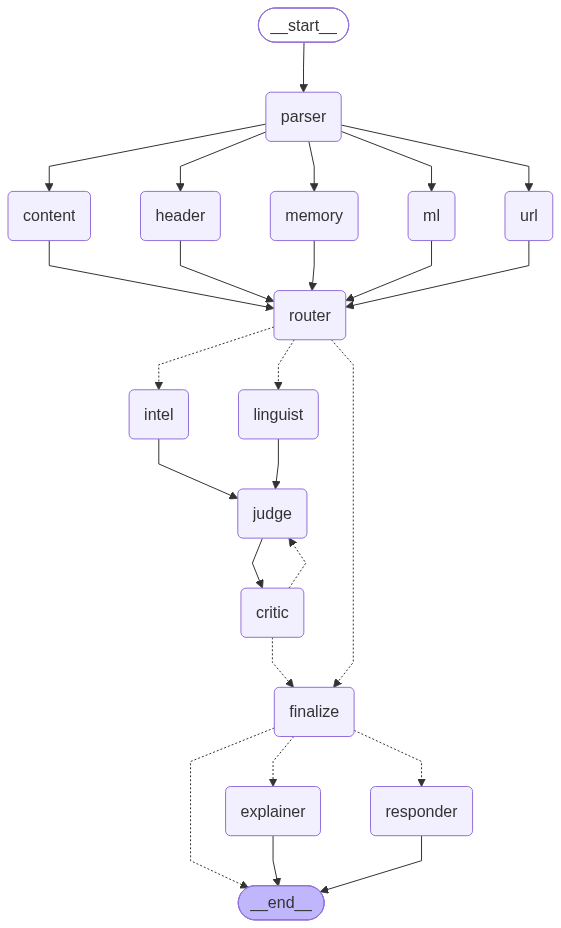

In [14]:
from langgraph.graph import StateGraph, START, END

g = StateGraph(State)
for name, fn in [("parser", parser_node), ("header", header_node), ("url", url_node), ("content", content_node),
                 ("ml", ml_node), ("memory", memory_node), ("router", router_node), ("linguist", linguist_node),
                 ("intel", intel_node), ("judge", judge_node), ("critic", critic_node), ("finalize", finalize_node),
                 ("explainer", explainer_node), ("responder", response_node)]:
    g.add_node(name, fn)

TOOL_AGENTS = ["header", "url", "content", "ml", "memory"]
g.add_edge(START, "parser")
for n in TOOL_AGENTS:
    g.add_edge("parser", n)                                   # parallel fan-out
g.add_edge(TOOL_AGENTS, "router")                             # join
g.add_conditional_edges("router", lambda s: ["linguist", "intel"] if s["route"] == "deep" else ["finalize"],
                        ["linguist", "intel", "finalize"])
g.add_edge(["linguist", "intel"], "judge")                    # join
g.add_edge("judge", "critic")
g.add_conditional_edges("critic", lambda s: "judge" if (not s["critic"]["agrees"] and s["rounds"] < 2) else "finalize",
                        ["judge", "finalize"])                # debate loop (max 1 rebuttal)
g.add_conditional_edges("finalize", lambda s: ["explainer", "responder"] if s.get("explain") else [END],
                        ["explainer", "responder", END])
g.add_edge("explainer", END); g.add_edge("responder", END)
APP = g.compile()

def analyze(raw, explain=False):
    return APP.invoke({"raw": raw, "explain": explain, "t0": time.perf_counter(), "signals": [], "trace": []})

try:
    from IPython.display import Image
    display(Image(APP.get_graph().draw_mermaid_png()))
except Exception as ex:
    print("(Graph image unavailable offline; Mermaid source below)\n", APP.get_graph().draw_mermaid())

### 9.1 Explanation report renderer
Each report contains the verdict, a risk gauge, the **highlighted email** (hover a highlight to see which agent flagged it), the evidence ledger, MITRE techniques with their citations, the debate transcript, the response playbook and an **agent timeline**.

In [15]:
CAT_COLORS = {"url": "#ffb4a2", "urgency": "#ffd166", "threat": "#ff9f80", "credential_request": "#ff6b6b", "financial_lure": "#f4a261",
              "reward_lure": "#e9c46a", "call_to_action": "#a0c4ff", "secrecy": "#cdb4db", "generic_greeting": "#e0e0e0",
              "bulk_mail_footer": "#d8e2dc", "reply_thread_context": "#b7e4c7", "llm": "#bde0fe"}

def highlight_body(state, max_chars=2200):
    e = state["email"]
    body, norm, idx = e["body"], e["norm"], e["idx"]
    spans = []
    for s in state["signals"]:
        for a, b in s["spans"]:
            if a < len(idx) and b - 1 < len(idx):
                spans.append((idx[a], idx[b - 1] + 1, s["category"], f"{s['agent']}: {s['name']} ({s['weight']:+.1f})"))
    for t in (state.get("linguist") or {}).get("tactics", []):
        q = str(t.get("quote", "")).strip().lower()
        if len(q) > 4:
            k = norm.lower().find(q)
            if k >= 0 and k + len(q) - 1 < len(idx):
                spans.append((idx[k], idx[k + len(q) - 1] + 1, "llm", f"SE Linguist: {t.get('principle')}: {t.get('why', '')}"))
    spans.sort(key=lambda z: (z[0], -(z[1] - z[0])))
    out, pos = [], 0
    for a, b, cat, tip in spans:
        if a < pos or a >= max_chars:
            continue
        out.append(html.escape(body[pos:a]))
        out.append(f'<mark title="{html.escape(tip)}" style="background:{CAT_COLORS.get(cat, "#ffe066")};color:#111;border-radius:3px;padding:0 2px">{html.escape(body[a:b])}</mark>')
        pos = b
    out.append(html.escape(body[pos:max_chars]) + ("…" if len(body) > max_chars else ""))
    rendered = "".join(out)
    # make homoglyphs / zero-width visible
    rendered = "".join(f'<span title="homoglyph of {CONFUSABLES[ch]}" style="color:#d1495b;text-decoration:underline wavy">{ch}</span>'
                       if ch in CONFUSABLES else ("<span title='zero-width char' style='color:#d1495b'>␣</span>" if ZW_RE.match(ch) else ch) for ch in rendered)
    return rendered.replace("\n", "<br>")

def render_report(state, title="Email analysis"):
    f, sc = state["final"], state["scores"]
    col = {"PHISHING": C["phish"], "SUSPICIOUS": C["warn"], "SAFE": C["legit"]}[f["tier"]]
    ex, rs = state.get("explanation") or {}, state.get("response") or {}
    ledger = "".join(f"<tr><td>{s['agent']}</td><td>{s['name']}</td><td style='text-align:right;color:{C['phish'] if s['weight']>0 else C['legit']}'><b>{s['weight']:+.1f}</b></td>"
                     f"<td>{html.escape(str(s['evidence']))[:110]}</td><td>{s['mitre'] or ''}</td></tr>" for s in sorted(state["signals"], key=lambda s: -abs(s["weight"])))
    techs = "".join(f"<li><b>{html.escape(str(t.get('id')))}</b> {html.escape(str(t.get('name', '')))} <span style='color:#666'>[{t.get('source_doc')}]</span>: {html.escape(str(t.get('evidence', '')))}</li>"
                    for t in (state.get("intel") or {}).get("techniques", []))
    debate = ""
    if state["route"] == "deep":
        j, c = state["judge"], state["critic"]
        debate = (f"<p><b>⚖️ Judge (round {state['rounds']}):</b> {html.escape(str(j.get('verdict')))} · p={j['phishing_probability']:.2f}. {html.escape(str(j.get('reasoning', '')))}</p>"
                  f"<p><b>🛑 Critic:</b> {'agrees' if c.get('agrees') else 'challenged: ' + html.escape(str(c.get('challenge', '')))}</p>")
    flags = "".join(f"<li><b>{html.escape(str(r.get('flag', '')))}</b>: {html.escape(str(r.get('detail', '')))}</li>" for r in ex.get("red_flags", []) if isinstance(r, dict))
    actions = "".join(f"<li>{html.escape(str(a))}</li>" for a in ex.get("safe_actions", []))
    play = "".join(f"<tr><td>{p['phase']}</td><td>{html.escape(p['step'])}</td><td>{p['owner']}</td></tr>" for p in rs.get("playbook", []))
    bar = lambda v, c: f"<div style='background:#eee;border-radius:4px;height:8px;width:160px;display:inline-block;vertical-align:middle'><div style='width:{v*100:.0f}%;background:{c};height:8px;border-radius:4px'></div></div> {v:.2f}"
    tbl = "border-collapse:collapse;font-size:12px;width:100%"
    out = f"""
<div style="font-family:Inter,Arial,sans-serif;border:1px solid #ddd;border-radius:10px;padding:16px;margin:8px 0;background:#fff;color:#222;max-width:980px">
 <div style="display:flex;justify-content:space-between;align-items:center;flex-wrap:wrap;gap:8px">
  <div><div style="font-size:12px;color:#666">{html.escape(title)}</div>
   <div style="font-size:24px;font-weight:700;color:{col}">{f['tier']} · {f['probability']:.0%}</div>
   <div style="font-size:12px;color:#666">route: <b>{f['route'].upper()} path</b> · {len(state['trace'])} agent steps · {max(t['end'] for t in state['trace']):.1f}s</div></div>
  <div style="font-size:12px;line-height:1.9">ML agent {bar(sc['ml'], C['blue'])}<br>Rule engine {bar(sc['rules'], C['purple'])}<br>Fused {bar(sc['fused'], col)}
   {'<br>Judge ' + bar(state['judge']['phishing_probability'], C['ink']) if state['route']=='deep' else ''}</div>
 </div>
 {f"<div style='background:#f6f8fa;border-left:4px solid {col};padding:8px 12px;margin:12px 0;font-size:14px'>{html.escape(str(ex.get('user_summary','')))}</div>" if ex else ''}
 <div style="display:grid;grid-template-columns:minmax(0,1.3fr) minmax(0,1fr);gap:14px">
  <div><h4 style="margin:6px 0">📧 Highlighted email</h4>
   <div style="font-family:Menlo,monospace;font-size:12px;background:#fafafa;border:1px solid #eee;padding:10px;border-radius:6px;max-height:300px;overflow:auto">{highlight_body(state)}</div></div>
  <div>{f'<h4 style="margin:6px 0">🚩 {"Red flags" if f["tier"]!="SAFE" else "Why it looks safe"}</h4><ul style="font-size:13px;padding-left:18px">{flags}</ul>' if flags else ''}
   {f'<h4 style="margin:6px 0">✅ What to do</h4><ul style="font-size:13px;padding-left:18px">{actions}</ul>' if actions else ''}
   {f'<h4 style="margin:6px 0">🎯 MITRE ATT&CK (grounded)</h4><ul style="font-size:12px;padding-left:18px">{techs}</ul>' if techs else ''}</div>
 </div>
 {f'<h4 style="margin:8px 0 4px">🗣️ Agent debate</h4><div style="font-size:12.5px">{debate}</div>' if debate else ''}
 <h4 style="margin:8px 0 4px">📒 Evidence ledger (log-odds)</h4>
 <table style="{tbl}"><tr style="background:#f1f3f5"><th>Agent</th><th>Signal</th><th>Weight</th><th>Evidence</th><th>MITRE</th></tr>{ledger or '<tr><td colspan=5>no deterministic signals</td></tr>'}</table>
 {f'<h4 style="margin:8px 0 4px">🧯 Response playbook (severity: {rs.get("severity")})</h4><table style="{tbl}"><tr style="background:#f1f3f5"><th>Phase</th><th>Step</th><th>Owner</th></tr>{play}</table>' if play else ''}
 {f'<p style="font-size:12px;color:#444"><b>Analyst note:</b> {html.escape(str(ex.get("analyst_summary","")))}</p>' if ex.get("analyst_summary") else ''}
</div>"""
    display(HTML(out))

def plot_timeline(state, title=""):
    tr = sorted(state["trace"], key=lambda t: t["start"])
    colors = {"tool": C["blue"], "ml": C["purple"], "router": C["grey"], "llm": C["warn"]}
    fig, ax = plt.subplots(figsize=(9, 0.32 * len(tr) + 0.8))
    for i, t in enumerate(tr):
        ax.barh(i, max(t["end"] - t["start"], 0.01), left=t["start"], color=colors[t["kind"]])
        ax.text(t["end"] + 0.02, i, t["note"], va="center", fontsize=7.5, color="#333")
    ax.set_yticks(range(len(tr))); ax.set_yticklabels([t["agent"] for t in tr], fontsize=8); ax.invert_yaxis()
    ax.set_xlabel("seconds"); ax.set_title(title or "Agent execution timeline (blue=tool, purple=ML, orange=LLM, grey=control)", fontsize=9)
    ax.set_xlim(0, max(t["end"] for t in tr) * 1.45 + 0.05)
    plt.tight_layout(); plt.show()

## 10. Live demonstration on real test-set emails
The emails below come straight from the **held-out test split** and are chosen automatically:
1. a phishing email the system is **highly confident** about (fast path),
2. an **ambiguous** phishing email that goes to the deep path (LLM agents + debate),
3. an **ambiguous legitimate** email (the hard false-positive case),
4. the same phishing email with a **homoglyph + zero-width evasion attack** applied.

In [16]:
t = time.perf_counter()
test_ml = ml_predict(test_df.text)
test_sig = [tool_signals(x) for x in test_df.text]
test_df = test_df.assign(ml=test_ml,
                         rule_lo=[rule_logodds(s) for _, s in test_sig],
                         obf=[e["obfuscation"]["zero_width"] + e["obfuscation"]["homoglyphs"] > 0 for e, _ in test_sig],
                         n_urls=[len(e["urls"]) for e, _ in test_sig])
test_df["fused"] = [fused_probability(m, r, o) for m, r, o in zip(test_df.ml, test_df.rule_lo, test_df.obf)]
test_df["route"] = np.where(((test_df.fused > LOW) & (test_df.fused < HIGH)) | test_df.obf, "deep", "fast")
print(f"Scored {len(test_df):,} test emails with tool agents + ML + fusion in {time.perf_counter()-t:.1f}s")
print(test_df.route.value_counts().to_dict())

def pick_case(cond, prefer_urls=True):
    cand = test_df[cond & (test_df.text.str.len().between(250, 1600))]
    if cand.empty:
        cand = test_df[cond]
    if prefer_urls and (cand.n_urls > 0).any():
        cand = cand[cand.n_urls > 0]
    return cand.sample(1, random_state=SEED).iloc[0]

case_confident = pick_case((test_df.label == 1) & (test_df.fused > 0.97) & (test_df.rule_lo > 2))
case_hard_phish = pick_case((test_df.label == 1) & (test_df.route == "deep"))
_legit_deep = test_df[(test_df.label == 0) & (test_df.route == "deep") & test_df.text.str.len().between(250, 2500)]
case_hard_legit = _legit_deep.sort_values("fused").iloc[-1]          # the most phishy-looking legitimate email
case_false_positive = test_df[test_df.label == 0].sort_values("fused").iloc[-1]   # worst false positive (used in Section 12)

Scored 3,487 test emails with tool agents + ML + fusion in 10.4s
{'fast': 3380, 'deep': 107}


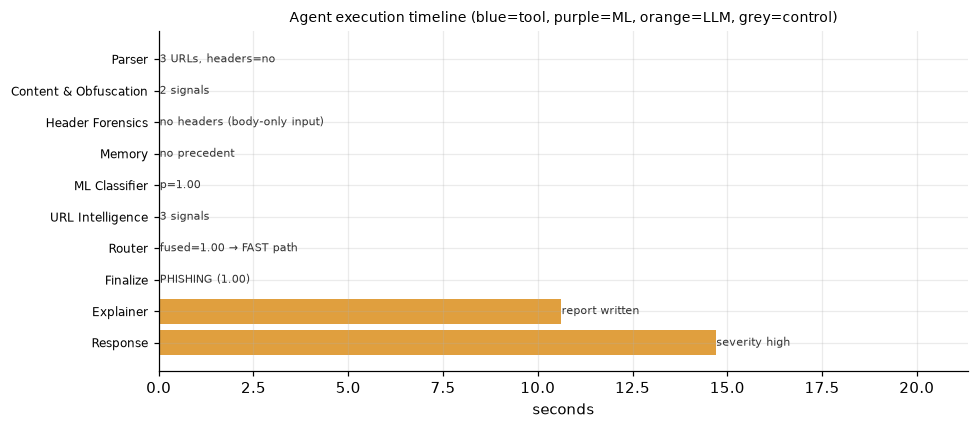

In [17]:
s1 = analyze(case_confident.text, explain=True)
render_report(s1, "Case 1: high-confidence phishing (true label: PHISHING)")
plot_timeline(s1)

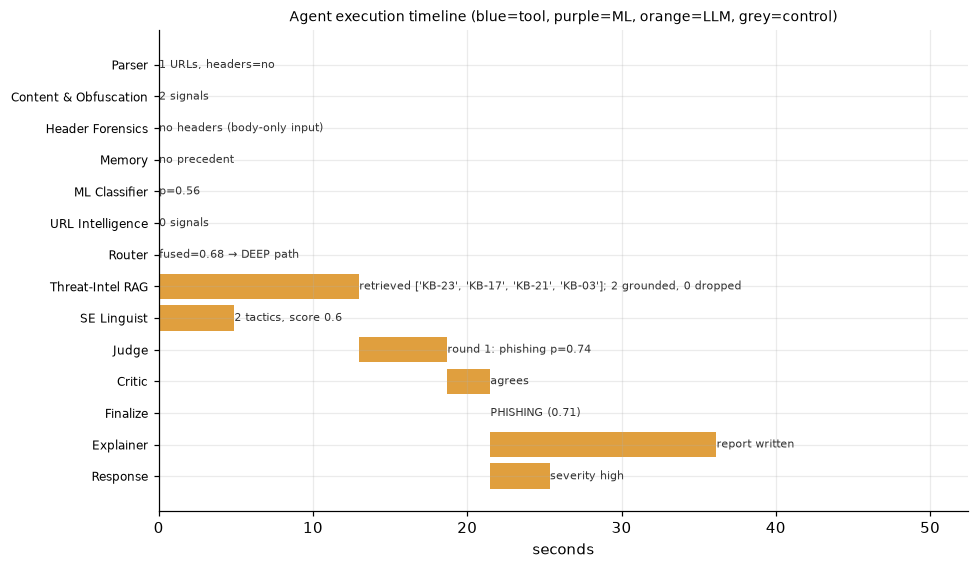

In [18]:
s2 = analyze(case_hard_phish.text, explain=True)
render_report(s2, "Case 2: ambiguous phishing → deep path (true label: PHISHING)")
plot_timeline(s2)

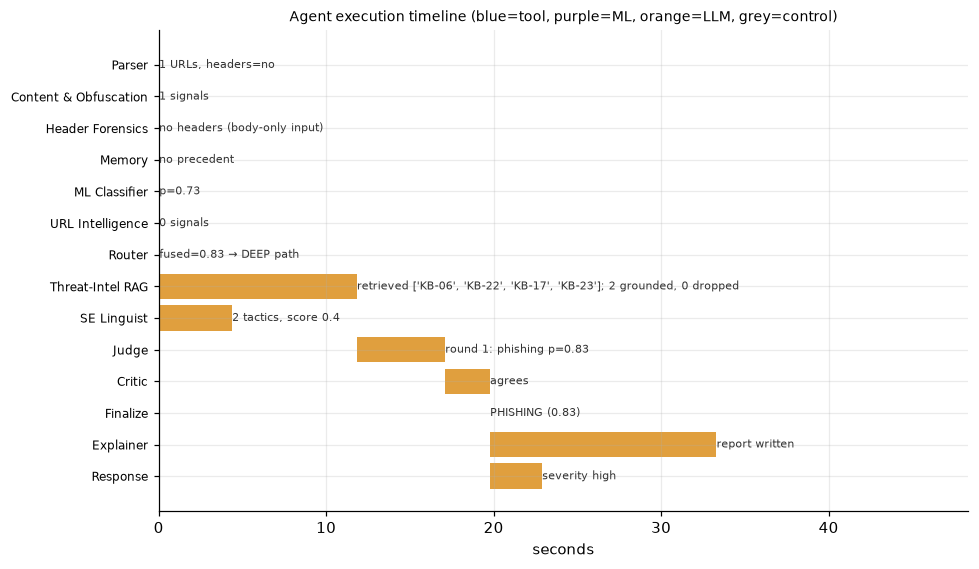

In [19]:
s3 = analyze(case_hard_legit.text, explain=True)
render_report(s3, "Case 3: ambiguous legitimate email → deep path (true label: SAFE)")
plot_timeline(s3)

> **Failure case, shown on purpose.** This is the *most phishy-looking legitimate email* in the test set: a newsletter welcome mail with "free membership", "special offers" and "click here to de-activate". Every component leaned towards phishing (ML 0.73, Judge 0.83), so the system got it wrong. Errors like this are exactly what the human-in-the-loop memory in Section 12 is for.

### 10.1 Evasion attack demo
We apply two filter-evasion transformations to Case 1: swapping Latin letters for Cyrillic look-alikes, and inserting zero-width characters inside words. A plain ML filter sees different characters. PhishSentinel's parser **undoes** the attack and also flags the obfuscation itself as evidence (MITRE T1027).

In [20]:
HOMO = {"a": "а", "e": "е", "o": "о", "c": "с", "p": "р", "i": "і", "s": "ѕ", "x": "х", "y": "у", "j": "ј"}
def homoglyph_attack(text, rate=0.9, seed=0):
    r = random.Random(seed)
    return "".join(HOMO[ch] if ch in HOMO and r.random() < rate else ch for ch in text)
def zero_width_attack(text, rate=0.9, seed=0):
    r = random.Random(seed)   # break each word into 2-character chunks with invisible separators
    return re.sub(r"\b(\w{3,})\b", lambda m: "\u200b".join(m.group(1)[k:k + 2] for k in range(0, len(m.group(1)), 2)) if r.random() < rate else m.group(1), text)
def combined_attack(text, seed=0):
    return zero_width_attack(homoglyph_attack(text, seed=seed), seed=seed)

attacked = combined_attack(case_confident.text)
print(f"ML filter WITHOUT normalisation: original p={ml_predict([case_confident.text], defend=False)[0]:.2f} → attacked p={ml_predict([attacked], defend=False)[0]:.2f}")
s4 = analyze(attacked, explain=True)
render_report(s4, "Case 4: Case 1 after homoglyph + zero-width evasion (true label: PHISHING)")

ML filter WITHOUT normalisation: original p=1.00 → attacked p=0.83


## 11. Evaluation
### 11.1 Whole test set
We compare four systems on all held-out test emails:
* **Rules only**: forensic tool agents (sigmoid of log-odds)
* **ML only**: TF-IDF + logistic regression
* **Fusion (no LLM)**: learned evidence fusion
* **PhishSentinel (agentic)**: fusion on the fast path plus LLM agents with debate on the deep path

Every deep-path email goes through the full LLM workflow. If the deep set is larger than `MAX_DEEP` (to bound runtime on local hardware), a stratified sample is used and the counts are reported.

In [21]:
MAX_DEEP = 150
deep_df = test_df[test_df.route == "deep"]
if len(deep_df) > MAX_DEEP:
    n_all = len(deep_df)
    deep_df = pd.concat([d.sample(max(1, round(MAX_DEEP * len(d) / n_all)), random_state=SEED) for _, d in deep_df.groupby("label")])
print(f"Deep-path emails in test set: {(test_df.route=='deep').sum()} | evaluated with full LLM pipeline: {len(deep_df)}")

deep_results, t_start = {}, time.perf_counter()
for i, (ix, row) in enumerate(deep_df.iterrows(), 1):
    st = analyze(row.text)
    deep_results[ix] = {"agentic": st["final"]["probability"], "judge": st["judge"]["phishing_probability"],
                        "critic_challenged": not st["critic"]["agrees"], "rounds": st["rounds"],
                        "grounded": len(st["intel"]["techniques"]), "dropped": st["intel"]["ungrounded_dropped"],
                        "latency": max(t["end"] for t in st["trace"])}
    if i % 10 == 0:
        llm.save(); print(f"  {i}/{len(deep_df)} done · {time.perf_counter()-t_start:.0f}s elapsed")
llm.save()
deep_res = pd.DataFrame.from_dict(deep_results, orient="index")
print("LLM telemetry:", llm.stats())

Deep-path emails in test set: 107 | evaluated with full LLM pipeline: 107


  10/107 done · 241s elapsed


  20/107 done · 486s elapsed


  30/107 done · 720s elapsed


  40/107 done · 918s elapsed


...

  70/107 done · 1599s elapsed


  80/107 done · 1800s elapsed


  90/107 done · 2016s elapsed


  100/107 done · 2228s elapsed


LLM telemetry: {'backend': 'ollama', 'model': 'llama3:latest', 'live_calls': 541, 'cache_hits': 8, 'failures': 0, 'avg_latency_s': 5.42}


In [22]:
def metrics(y, p, name):
    yhat = (np.asarray(p) >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat, labels=[0, 1]).ravel()
    return {"system": name, "accuracy": accuracy_score(y, yhat), "precision": precision_score(y, yhat, zero_division=0),
            "recall": recall_score(y, yhat), "F1": f1_score(y, yhat), "ROC-AUC": roc_auc_score(y, p) if len(set(y)) > 1 else np.nan,
            "false-positive rate": fp / max(fp + tn, 1), "FP": fp, "FN": fn}

test_df["rules"] = [sigmoid(lo - 1.0) for lo in test_df.rule_lo]
# Agentic score: fast-path emails keep the fused score; evaluated deep-path emails use the agentic score
eval_df = test_df[(test_df.route == "fast") | test_df.index.isin(deep_res.index)].copy()
eval_df["agentic"] = eval_df.fused
eval_df.loc[deep_res.index, "agentic"] = deep_res.agentic

overall = pd.DataFrame([metrics(eval_df.label, eval_df[c], n) for c, n in
                        [("rules", "Rules only"), ("ml", "ML only"), ("fused", "Fusion (no LLM)"), ("agentic", "PhishSentinel (agentic)")]])
print(f"Evaluation set: {len(eval_df):,} emails ({(eval_df.route=='fast').sum():,} fast-path + {len(deep_res)} deep-path)")
display(overall.style.format({c: "{:.4f}" for c in ["accuracy", "precision", "recall", "F1", "ROC-AUC", "false-positive rate"]})
        .highlight_max(subset=["accuracy", "F1", "ROC-AUC"], color="#d8f3dc"))

Evaluation set: 3,487 emails (3,380 fast-path + 107 deep-path)


,system,accuracy,precision,recall,F1,ROC-AUC,false-positive rate,FP,FN
0,Rules only,0.6866,0.8392,0.2002,0.3232,0.7530,0.0229,50,1043
1,ML only,0.9865,0.9772,0.9870,0.9821,0.9988,0.0137,30,17
2,Fusion (no LLM),0.9874,0.9809,0.9854,0.9832,0.9988,0.0115,25,19
3,PhishSentinel (agentic),0.9874,0.9831,0.9831,0.9831,0.9988,0.0101,22,22


### 11.2 The hard cases: where the agents earn their cost
Fast-path emails are already near-perfect, so headline metrics hide the LLM's contribution. The **deep-path (ambiguous) subset** is where the systems really differ.

In [23]:
hard = eval_df.loc[deep_res.index].join(deep_res[["judge"]])
hard_table = pd.DataFrame([metrics(hard.label, hard[c], n) for c, n in
                           [("rules", "Rules only"), ("ml", "ML only"), ("fused", "Fusion (no LLM)"), ("judge", "LLM Judge alone"), ("agentic", "PhishSentinel (agentic)")]])
print(f"Hard subset: {len(hard)} emails ({int(hard.label.sum())} phishing / {int((1-hard.label).sum())} safe)")
display(hard_table.style.format({c: "{:.3f}" for c in ["accuracy", "precision", "recall", "F1", "ROC-AUC", "false-positive rate"]})
        .highlight_max(subset=["accuracy", "F1"], color="#d8f3dc"))

Hard subset: 107 emails (52 phishing / 55 safe)


,system,accuracy,precision,recall,F1,ROC-AUC,false-positive rate,FP,FN
0,Rules only,0.523,0.545,0.115,0.190,0.487,0.091,5,46
1,ML only,0.757,0.697,0.885,0.780,0.852,0.364,20,6
2,Fusion (no LLM),0.785,0.746,0.846,0.793,0.839,0.273,15,8
3,LLM Judge alone,0.729,0.702,0.769,0.734,0.764,0.309,17,12
4,PhishSentinel (agentic),0.785,0.774,0.788,0.781,0.815,0.218,12,11


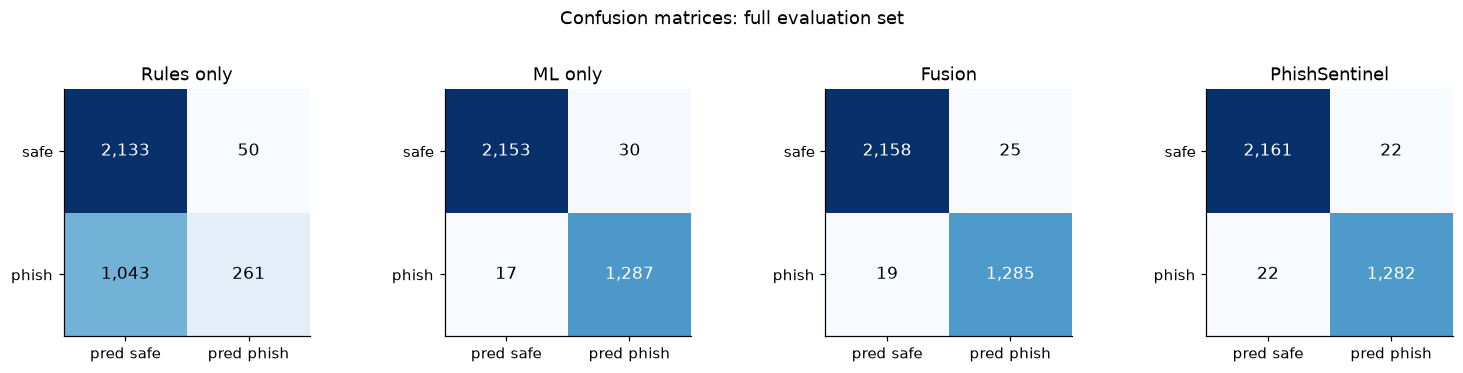

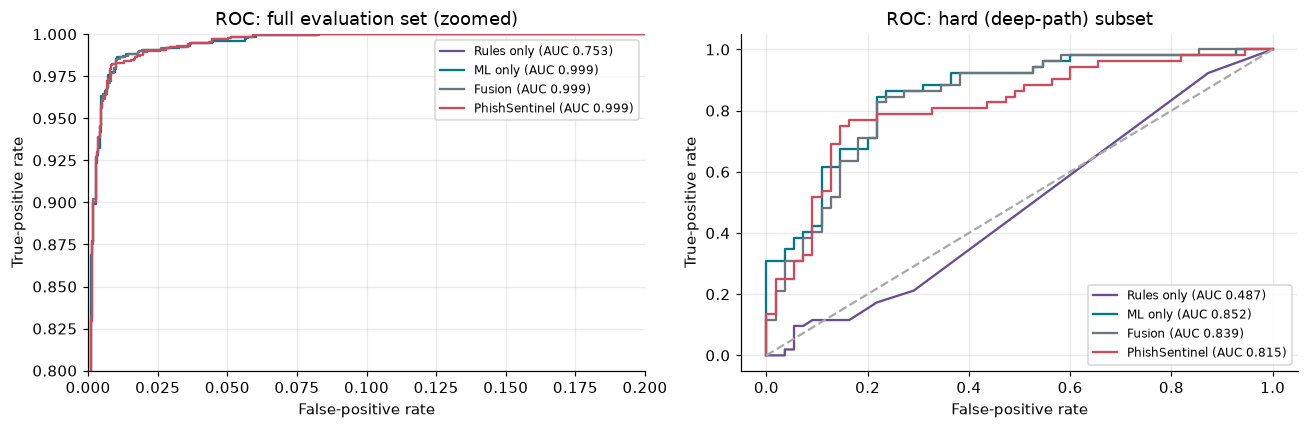

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (c, n) in zip(axes, [("rules", "Rules only"), ("ml", "ML only"), ("fused", "Fusion"), ("agentic", "PhishSentinel")]):
    cm = confusion_matrix(eval_df.label, eval_df[c] >= 0.5)
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for (a, b), v in np.ndenumerate(cm):
        ax.text(b, a, f"{v:,}", ha="center", va="center", color="white" if v > cm.max() / 2 else "black", fontsize=11)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["pred safe", "pred phish"]); ax.set_yticks([0, 1]); ax.set_yticklabels(["safe", "phish"])
    ax.set_title(n)
plt.suptitle("Confusion matrices: full evaluation set", y=1.03); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c, n, col in [("rules", "Rules only", C["purple"]), ("ml", "ML only", C["blue"]), ("fused", "Fusion", C["grey"]), ("agentic", "PhishSentinel", C["phish"])]:
    fpr, tpr, _ = roc_curve(eval_df.label, eval_df[c]); ax[0].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(eval_df.label, eval_df[c]):.3f})", color=col)
    fpr, tpr, _ = roc_curve(hard.label, hard[c]); ax[1].plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(hard.label, hard[c]):.3f})", color=col)
for a, t in zip(ax, ["ROC: full evaluation set", "ROC: hard (deep-path) subset"]):
    a.plot([0, 1], [0, 1], "--", color="#aaa"); a.set_title(t); a.set_xlabel("False-positive rate"); a.set_ylabel("True-positive rate"); a.legend(fontsize=8)
ax[0].set_xlim(0, 0.2); ax[0].set_ylim(0.8, 1.0); ax[0].set_title("ROC: full evaluation set (zoomed)")
plt.tight_layout(); plt.show()

### 11.3 Agent behaviour and cost
These measures show what the multi-agent design actually does: how many emails need LLM reasoning, how often the Critic challenges the Judge, how many made-up citations the grounding check removes, and how long each path takes.

,metric,value
0,Emails settled on fast path (no LLM),96.9%
1,Emails escalated to deep path,3.1%
2,LLM calls avoided vs. always-deep (≈4.2 calls/email),"14,196"
3,Critic challenged the Judge,19.6%
4,Debates that needed a rebuttal round,45.8%
5,Grounded MITRE citations per deep case,1.63
6,Ungrounded citations dropped (total),2 of 176
7,Median deep-path latency (s),21.3


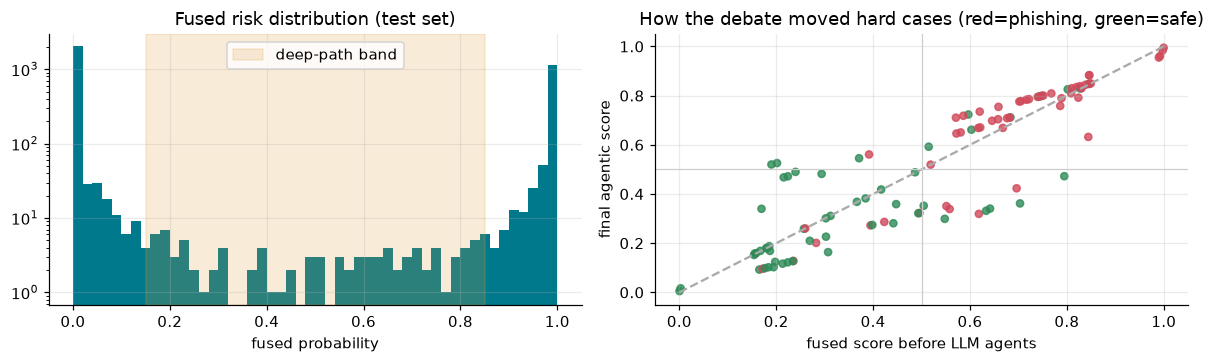

In [25]:
n_fast, n_deep_total = (test_df.route == "fast").sum(), (test_df.route == "deep").sum()
behaviour = pd.DataFrame([
    {"metric": "Emails settled on fast path (no LLM)", "value": f"{n_fast / len(test_df):.1%}"},
    {"metric": "Emails escalated to deep path", "value": f"{n_deep_total / len(test_df):.1%}"},
    {"metric": "LLM calls avoided vs. always-deep (≈4.2 calls/email)", "value": f"{n_fast * 4.2:,.0f}"},
    {"metric": "Critic challenged the Judge", "value": f"{deep_res.critic_challenged.mean():.1%}"},
    {"metric": "Debates that needed a rebuttal round", "value": f"{(deep_res.rounds > 1).mean():.1%}"},
    {"metric": "Grounded MITRE citations per deep case", "value": f"{deep_res.grounded.mean():.2f}"},
    {"metric": "Ungrounded citations dropped (total)", "value": f"{int(deep_res.dropped.sum())} of {int(deep_res.grounded.sum() + deep_res.dropped.sum())}"},
    {"metric": "Median deep-path latency (s)", "value": f"{deep_res.latency.median():.1f}"},
])
display(behaviour)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(test_df.fused, bins=50, color=C["blue"]); ax[0].axvspan(LOW, HIGH, color=C["warn"], alpha=0.2, label="deep-path band")
ax[0].set_yscale("log"); ax[0].set_title("Fused risk distribution (test set)"); ax[0].set_xlabel("fused probability"); ax[0].legend()
moved = hard.assign(delta=hard.agentic - hard.fused)
ax[1].scatter(moved.fused, moved.agentic, c=[C["phish"] if l else C["legit"] for l in moved.label], s=22, alpha=0.8)
ax[1].plot([0, 1], [0, 1], "--", color="#aaa"); ax[1].axhline(0.5, color="#ccc", lw=0.8); ax[1].axvline(0.5, color="#ccc", lw=0.8)
ax[1].set_xlabel("fused score before LLM agents"); ax[1].set_ylabel("final agentic score"); ax[1].set_title("How the debate moved hard cases (red=phishing, green=safe)")
plt.tight_layout(); plt.show()

### 11.4 Adversarial robustness
We apply evasion attacks to **every phishing email in the test set** and measure the detection rate (recall at threshold 0.5). These systems run without the LLM, so the full set can be scored in seconds:
* **ML (no defence)**: raw text into the classifier
* **ML + normalisation**: PhishSentinel's parser undoes homoglyphs and zero-width characters first
* **PhishSentinel fusion**: normalised ML plus rules plus the obfuscation signal

,ML (no defence),ML + normalisation,PhishSentinel fusion
attack,,,
none,98.7%,98.7%,98.5%
homoglyph,80.8%,98.7%,98.8%
zero-width,100.0%,98.7%,98.8%
combined,100.0%,98.7%,98.8%


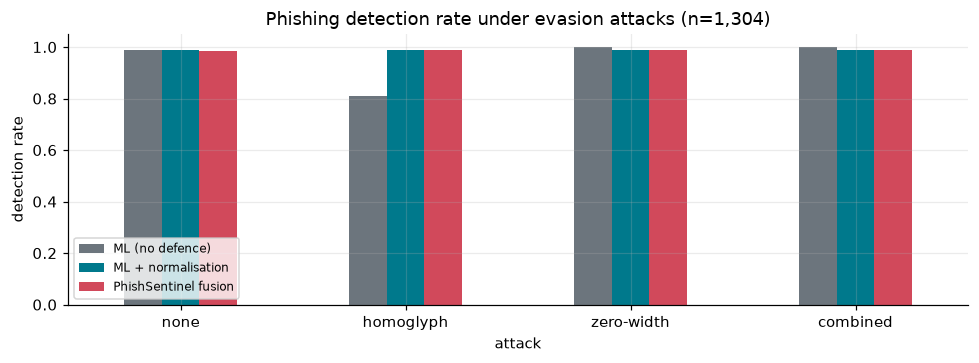

In [26]:
phish_test = test_df[test_df.label == 1].text.tolist()
attacks = {"none": lambda t: t, "homoglyph": homoglyph_attack, "zero-width": zero_width_attack, "combined": combined_attack}
rob_rows = []
for an, fn in attacks.items():
    adv = [fn(t, seed=i) if an != "none" else t for i, t in enumerate(phish_test)]
    p_raw, p_def = ml_predict(adv, defend=False), ml_predict(adv, defend=True)
    p_fus = []
    for t, pd_ in zip(adv, p_def):
        e, s = tool_signals(t)
        p_fus.append(fused_probability(pd_, rule_logodds(s), e["obfuscation"]["zero_width"] + e["obfuscation"]["homoglyphs"] > 0))
    rob_rows.append({"attack": an, "ML (no defence)": (p_raw >= 0.5).mean(), "ML + normalisation": (p_def >= 0.5).mean(),
                     "PhishSentinel fusion": (np.array(p_fus) >= 0.5).mean()})
robust = pd.DataFrame(rob_rows).set_index("attack")
display(robust.style.format("{:.1%}"))
robust.plot.bar(figsize=(9, 3.4), color=[C["grey"], C["blue"], C["phish"]], rot=0)
plt.title(f"Phishing detection rate under evasion attacks (n={len(phish_test):,})"); plt.ylabel("detection rate"); plt.ylim(0, 1.05)
plt.legend(loc="lower left", fontsize=8); plt.tight_layout(); plt.show()

**Reading the results.**
* **Homoglyphs are the real threat:** detection by the plain ML filter falls from 98.7% to **80.8%**, because Cyrillic look-alikes break its word and character n-grams. PhishSentinel's normalisation brings it back to **98.8%**.
* **Zero-width noise backfires on the attacker** with this model: text broken into two-letter chunks looks so unusual that the plain classifier flags *every* such email (100%). PhishSentinel also flags it explicitly as evasion (`unicode_obfuscation`, MITRE T1027) and sends it to the deep path, so the alarm comes with a reason.
* With normalisation the detection rate is **the same under every attack**, which means the defence fully cancels these evasions.

## 12. Human-in-the-loop: the system learns from an analyst
We take the **worst false positive** in the test set (the legitimate email with the highest risk score) and record an analyst's correction in memory. We then analyse a **lightly edited copy** of it, for example the same sender writing again. The Memory agent finds the precedent (semantic similarity) and the verdict changes **without any retraining**.

In [27]:
before = analyze(case_false_positive.text)
memory.add(case_false_positive.text, "legitimate", "Analyst verified with sender by phone: routine business correspondence")
variant = case_false_positive.text.replace(".", " .", 3) + "\n\nthanks again ."
after = analyze(variant)
display(pd.DataFrame([
    {"run": "before feedback", "fused": before["scores"]["fused"], "final": before["final"]["probability"], "tier": before["final"]["tier"], "route": before["route"], "memory": "-"},
    {"run": "after feedback (edited copy)", "fused": after["scores"]["fused"], "final": after["final"]["probability"], "tier": after["final"]["tier"], "route": after["route"],
     "memory": f"{after['memory']['label']} (sim {after['memory']['similarity']})" if after.get("memory") else "-"}]).round(3))
memory = FeedbackMemory()  # reset so later runs are unaffected

,run,fused,final,tier,route,memory
0,before feedback,0.999,0.999,PHISHING,fast,-
1,after feedback (edited copy),0.229,0.605,SUSPICIOUS,deep,legitimate (sim 1.0)


**Result.** One analyst correction moved the worst false positive from **PHISHING (0.999) to SUSPICIOUS (0.605)**. The fused pre-LLM risk fell to 0.23, which sent the case to the deep path. The LLM Judge saw the precedent but stayed cautious because the email still contains strong spam-like signals. That conservative behaviour is a reasonable safety property: memory lowers the alarm level and routes the case for review, but it never silently clears it.

## 13. Try it yourself
`analyze()` accepts either plain email text or a **full raw email** with headers. With headers, the Header Forensics agent also checks SPF/DKIM/DMARC, Reply-To and attachments. Paste any email into `MY_EMAIL` and run the cell. An optional Gradio web UI follows.

In [28]:
MY_EMAIL = test_df[(test_df.label == 0) & (test_df.route == "fast")].text.iloc[3]   # ← replace with your own email text
st = analyze(MY_EMAIL, explain=True)
render_report(st, "Your email")

In [29]:
LAUNCH_UI = False   # set True in Colab to get a shareable web demo
if LAUNCH_UI:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
    import gradio as gr
    def ui_analyze(text):
        s = analyze(text, explain=True)
        ex = s.get("explanation") or {}
        flags = "\n".join(f"- **{r.get('flag')}**: {r.get('detail')}" for r in ex.get("red_flags", []) if isinstance(r, dict))
        return (f"## {s['final']['tier']} ({s['final']['probability']:.0%})\n{ex.get('user_summary', '')}\n\n{flags}",
                pd.DataFrame(s["signals"])[["agent", "name", "weight", "evidence"]] if s["signals"] else pd.DataFrame(),
                json.dumps(s.get("response", {}).get("iocs", {}), indent=2))
    gr.Interface(fn=ui_analyze, inputs=gr.Textbox(lines=14, label="Paste email (plain text or raw MIME)"),
                 outputs=[gr.Markdown(label="Verdict"), gr.Dataframe(label="Evidence ledger"), gr.Code(label="IOCs (JSON)", language="json")],
                 title="🛡️ PhishSentinel", description="Agentic phishing detection & explanation").launch(share=True)

## 14. Results summary and conclusions

In [30]:
o = overall.set_index("system"); h = hard_table.set_index("system")
display(Markdown(f"""
| | Full evaluation set | Hard (deep-path) subset |
|---|---|---|
| **ML only** F1 | {o.loc['ML only','F1']:.4f} | {h.loc['ML only','F1']:.3f} |
| **Fusion (no LLM)** F1 | {o.loc['Fusion (no LLM)','F1']:.4f} | {h.loc['Fusion (no LLM)','F1']:.3f} |
| **PhishSentinel (agentic)** F1 | **{o.loc['PhishSentinel (agentic)','F1']:.4f}** | **{h.loc['PhishSentinel (agentic)','F1']:.3f}** |
| PhishSentinel false-positive rate | {o.loc['PhishSentinel (agentic)','false-positive rate']:.4f} | {h.loc['PhishSentinel (agentic)','false-positive rate']:.3f} |
| Share of emails needing an LLM | {n_deep_total/len(test_df):.1%} | 100% |
| Homoglyph-attack detection: ML (no defence) → PhishSentinel | {robust.loc['homoglyph','ML (no defence)']:.1%} → **{robust.loc['homoglyph','PhishSentinel fusion']:.1%}** | |
| Hybrid RAG Hit@3 | {retrieval_table.set_index('retriever').loc['hybrid','Hit@3']:.2f} | |
"""))
print("LLM telemetry:", llm.stats())


| | Full evaluation set | Hard (deep-path) subset |
|---|---|---|
| **ML only** F1 | 0.9821 | 0.780 |
| **Fusion (no LLM)** F1 | 0.9832 | 0.793 |
| **PhishSentinel (agentic)** F1 | **0.9831** | **0.781** |
| PhishSentinel false-positive rate | 0.0101 | 0.218 |
| Share of emails needing an LLM | 3.1% | 100% |
| Homoglyph-attack detection: ML (no defence) → PhishSentinel | 80.8% → **98.8%** | |
| Hybrid RAG Hit@3 | 0.93 | |


LLM telemetry: {'backend': 'ollama', 'model': 'llama3:latest', 'live_calls': 546, 'cache_hits': 8, 'failures': 0, 'avg_latency_s': 5.43}


**Key takeaways**
1. **Agents are layered, not just stacked.** Cheap deterministic tools and the ML agent settle most emails at once. LLM reasoning is used only where it adds information, so the system can run at scale.
2. **The LLM agents mainly reduce false alarms.** On the full test set PhishSentinel has the fewest false positives (22 vs 30 for ML alone, 1.0% FPR). On the 107 hard cases the false-positive rate falls from 36.4% (ML) to 21.8%. The cost is slightly lower recall on hard cases (0.79 vs 0.88), and the LLM Judge alone (F1 0.73) is weaker than the fused system. So the agents add value as *one voice in an ensemble*, not as a replacement for the ML model.
3. **Explanations are evidence-based.** Each verdict comes with a log-odds ledger, highlighted spans and grounded MITRE citations. Analysts can audit *why*, not only *what*.
4. **Robustness by design.** A pure ML filter is fragile against Unicode evasion. Normalisation plus treating obfuscation as a signal restores detection.
5. **A learning SOC.** Analyst feedback changes future decisions through vector memory, with no retraining.

**Limitations and honest notes**
* The public dataset is body-only and lower-cased/tokenised. Header forensics (SPF/DKIM/DMARC, Reply-To, attachments) is implemented and runs on raw emails, but the benchmark cannot measure it. Part of the "phishing" class is generic malicious spam.
* Deep-path metrics depend on the LLM. They were measured with an 8-billion-parameter local model, and larger models (e.g. via Groq or Gemini) are expected to do better in the Judge and Critic roles.
* The knowledge base is a curated summary (24 documents). A production system would index the full MITRE ATT&CK STIX feed and live threat-intelligence sources (URL reputation, WHOIS domain age).

**Future work:** live URL detonation and sandboxing, domain-age and reputation lookups, QR-code decoding of image attachments, vision-language analysis of rendered HTML, and active learning from analyst feedback.